In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from decimal import Decimal, getcontext
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, PolynomialFeatures
from sklearn.metrics import classification_report,accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [3]:
FW_FILE_PATH = []
GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = './Dissertation/'
GOOGLE_DRIVE_PATH = os.path.join('gdrive', 'MyDrive', GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)
print('List files: ', os.listdir(GOOGLE_DRIVE_PATH))

DATA_PATH_INTER = os.path.join(GOOGLE_DRIVE_PATH, 'Datasets')
DataFile = os.path.join(DATA_PATH_INTER, 'final_dataset.csv')
print(f"File: {DataFile}")

models = []
accuracy = []
recall = []
precision = []
f1score = []

regression_esults = {
    'Model': [],
    'R-squared': [],
    'RMSE': []
}

List files:  ['Datasets', 'DissertationFinalCode.ipynb']
File: gdrive/MyDrive/./Dissertation/Datasets/final_dataset.csv


In [4]:
PlayerData = pd.read_csv(DataFile)
print(PlayerData.head())

           Player                 Club  Age Position   Nation      Value  \
0   Kylian Mbappe  Paris Saint-Germain   22   attack   France  144000000   
1  Erling Haaland    Borussia Dortmund   21   attack   Norway  117000000   
2      Harry Kane    Tottenham Hotspur   28   attack  England  108000000   
3    Jadon Sancho    Manchester United   21   attack  England   90000000   
4   Mohamed Salah         Liverpool FC   29   attack    Egypt   90000000   

  Contract Years Left          League Squad (20/21)  MP (20/21)  ...  \
0                   1         Ligue 1     Paris S-G        31.0  ...   
1                   3      Bundesliga      Dortmund        28.0  ...   
2                   3  Premier League     Tottenham        35.0  ...   
3                   5  Premier League      Dortmund        26.0  ...   
4                   2  Premier League     Liverpool        37.0  ...   

   Offsides (17/18)  Crosses (17/18)  Interceptions (17/18)  \
0              23.0             62.0           

In [5]:
total_missing_values = PlayerData.isnull().sum()
print("Missing values before cleaning:")
print(total_missing_values[total_missing_values > 0])

Missing values before cleaning:
Squad (20/21)                           165
MP (20/21)                              165
Starts (20/21)                          165
Min (20/21)                             165
Total Mins/90 (20/21)                   165
                                       ... 
Own Goals (17/18)                       921
Total Loose Balls Recovered (17/18)     919
Aerial Duel Won (17/18)                 919
Aerial Duel Lost (17/18)                919
% Aerial Duels Won (17/18)             1023
Length: 540, dtype: int64


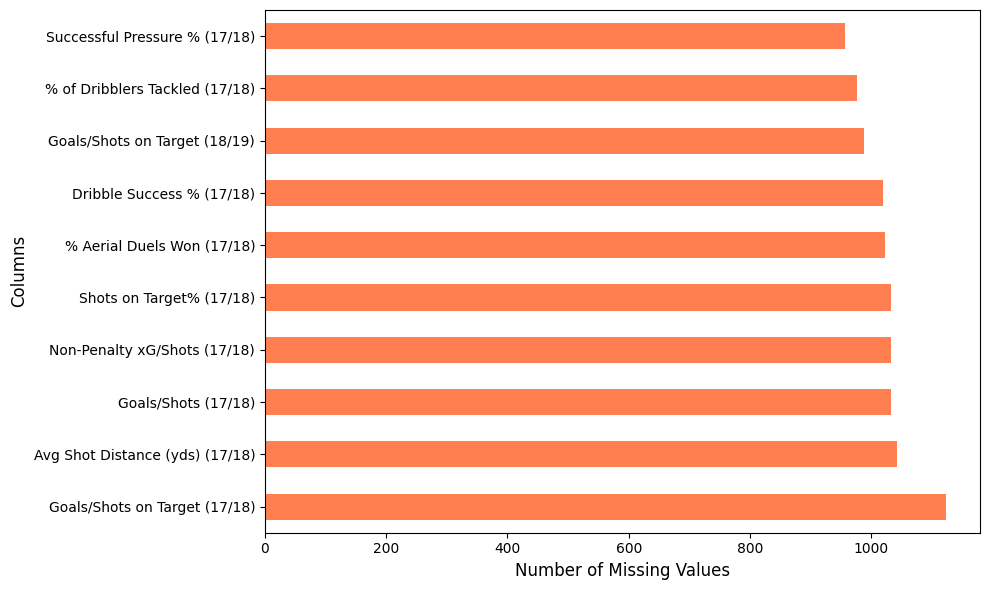

In [6]:
# Sort the missing values in descending order and select the top 10 columns
missing_values_sorted_top10 = total_missing_values.sort_values(ascending=False).head(10)

# Plot a horizontal bar graph to visualize the top 10 columns with missing values
plt.figure(figsize=(10, 6))  # Set the figure size
missing_values_sorted_top10.plot(kind='barh', color='coral')  # Use barh for horizontal bar chart

# Add labels and title
#plt.title('Top 10 Columns with Missing Values (Descending Order)', fontsize=16)
plt.xlabel('Number of Missing Values', fontsize=12)
plt.ylabel('Columns', fontsize=12)

# Display the graph
plt.tight_layout()  # Adjust layout for better spacing
plt.show()


In [7]:
# Ensure uniform data types
PlayerData = PlayerData.convert_dtypes()

def replace_zero_na(df):
    for column in df.columns:
        if pd.api.types.is_numeric_dtype(df[column]):
            df[column] = pd.to_numeric(df[column], errors='coerce')  # Ensure column is numeric
            df[column].replace(0, np.nan, inplace=True)  # Replace 0 with NaN
            if pd.api.types.is_integer_dtype(df[column].dtype):
                df[column].fillna(int(df[column].mean()), inplace=True)  # Replace NaN with column mean, cast to int
            else:
                df[column].fillna(df[column].mean(), inplace=True)  # Replace NaN with column mean
        else:
            df[column] = df[column].astype(str).replace('nan', 'Unknown')  # Replace NaN with 'Unknown'
    return df

# Apply the function
FinalPlayerData = replace_zero_na(PlayerData)
FinalPlayerData['Contract Years Left'] = FinalPlayerData['Contract Years Left'].replace('fail', '0')
FinalPlayerData.to_csv('gdrive/MyDrive/./Dissertation/Datasets/FinalPlayerData.csv', index=False)

In [8]:
total_missing_values = FinalPlayerData.isnull().sum()
print("Missing values after cleaning:")
print(total_missing_values[total_missing_values > 0])

Missing values after cleaning:
Series([], dtype: int64)


In [9]:
print("Head of the cleaned data:")
FinalPlayerData.head()

Head of the cleaned data:


,Player,Club,Age,Position,Nation,Value,Contract Years Left,League,Squad (20/21),MP (20/21),...,Offsides (17/18),Crosses (17/18),Interceptions (17/18),Penalty Kicks Won (17/18),Penalties Conceded (17/18),Own Goals (17/18),Total Loose Balls Recovered (17/18),Aerial Duel Won (17/18),Aerial Duel Lost (17/18),% Aerial Duels Won (17/18)
0,Kylian Mbappe,Paris Saint-Germain,22,attack,France,144000000,1,Ligue 1,Paris S-G,31,...,23,62,1,1,1,1,98,1,4,20.0
1,Erling Haaland,Borussia Dortmund,21,attack,Norway,117000000,3,Bundesliga,Dortmund,28,...,6,27,20,1,1,1,171,27,27,47.916081
2,Harry Kane,Tottenham Hotspur,28,attack,England,108000000,3,Premier League,Tottenham,35,...,43,24,7,1,1,1,124,69,111,38.3
3,Jadon Sancho,Manchester United,21,attack,England,90000000,5,Premier League,Dortmund,26,...,1,15,6,1,1,1,57,3,14,17.6
4,Mohamed Salah,Liverpool FC,29,attack,Egypt,90000000,2,Premier League,Liverpool,37,...,18,50,13,1,1,1,219,19,58,24.7


In [10]:
print("Tail of the cleaned data:")
FinalPlayerData.tail()

Tail of the cleaned data:


,Player,Club,Age,Position,Nation,Value,Contract Years Left,League,Squad (20/21),MP (20/21),...,Offsides (17/18),Crosses (17/18),Interceptions (17/18),Penalty Kicks Won (17/18),Penalties Conceded (17/18),Own Goals (17/18),Total Loose Balls Recovered (17/18),Aerial Duel Won (17/18),Aerial Duel Lost (17/18),% Aerial Duels Won (17/18)
2070,Matis Carvalho,Montpellier HSC,22,Goalkeeper,Portugal,180000,1,Ligue 1,<NA>,24,...,6,27,20,1,1,1,171,27,27,47.916081
2071,Lorenzo Andrenacci,Genoa CFC,26,Goalkeeper,Italy,135000,3,Serie A,<NA>,24,...,6,27,20,1,1,1,171,27,27,47.916081
2072,Mamadou Doucoure,Borussia Mönchengladbach,23,Defender,France,90000,3,Bundesliga,<NA>,24,...,6,27,20,1,1,1,171,27,27,47.916081
2073,Michael Langer,FC Schalke 04,36,Goalkeeper,Austria,90000,1,Bundesliga,Schalke 04,3,...,6,27,20,1,1,1,171,27,27,47.916081
2074,Gianluca Pegolo,US Sassuolo,40,Goalkeeper,Italy,90000,1,Serie A,<NA>,24,...,6,27,20,1,1,1,7,27,27,47.916081


In [11]:
# Display basic information about the dataset
print("Basic Information:")
print(FinalPlayerData.info(20))

Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 548 columns):
 #    Column                                                                      Dtype  
---   ------                                                                      -----  
 0    Player                                                                      object 
 1    Club                                                                        object 
 2    Age                                                                         Int64  
 3    Position                                                                    object 
 4    Nation                                                                      object 
 5    Value                                                                       Int64  
 6    Contract Years Left                                                         object 
 7    League                                                   

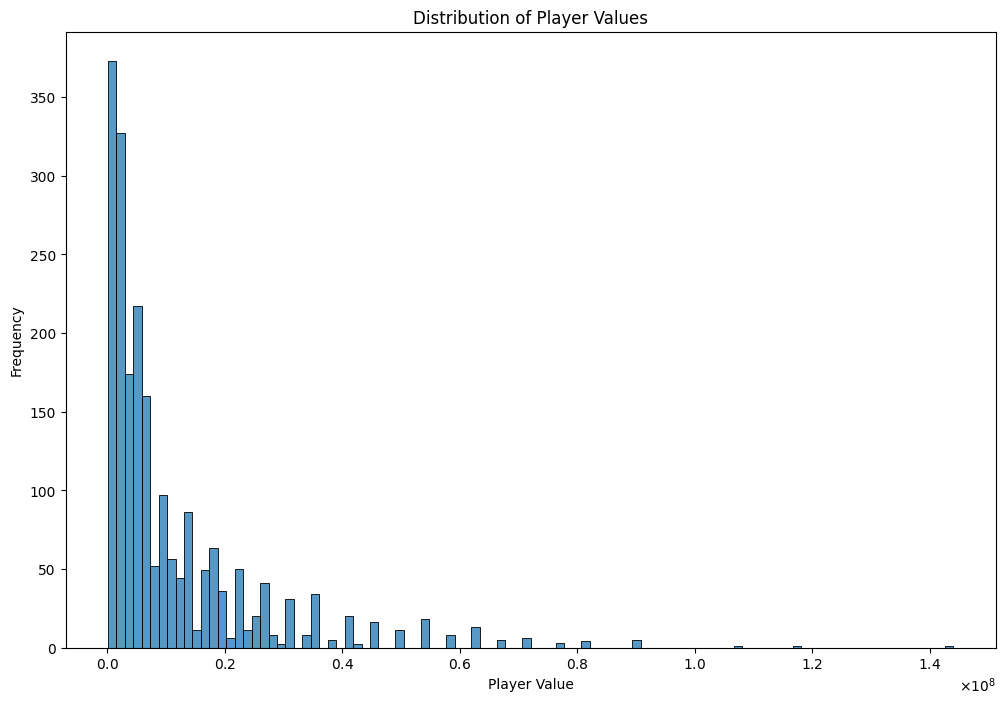

In [12]:
import matplotlib.ticker as ticker

# Assuming 'df' is your dataframe and 'Value' is the column for player values
plt.figure(figsize=(12, 8))

# Plotting the histogram with KDE
sns.histplot(FinalPlayerData['Value'], bins=100)

# Adding title and labels
plt.title('Distribution of Player Values')
plt.xlabel('Player Value')
plt.ylabel('Frequency')

# Formatting the x-axis to scientific notation
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().xaxis.set_major_formatter(formatter)

# Display the plot
plt.show()

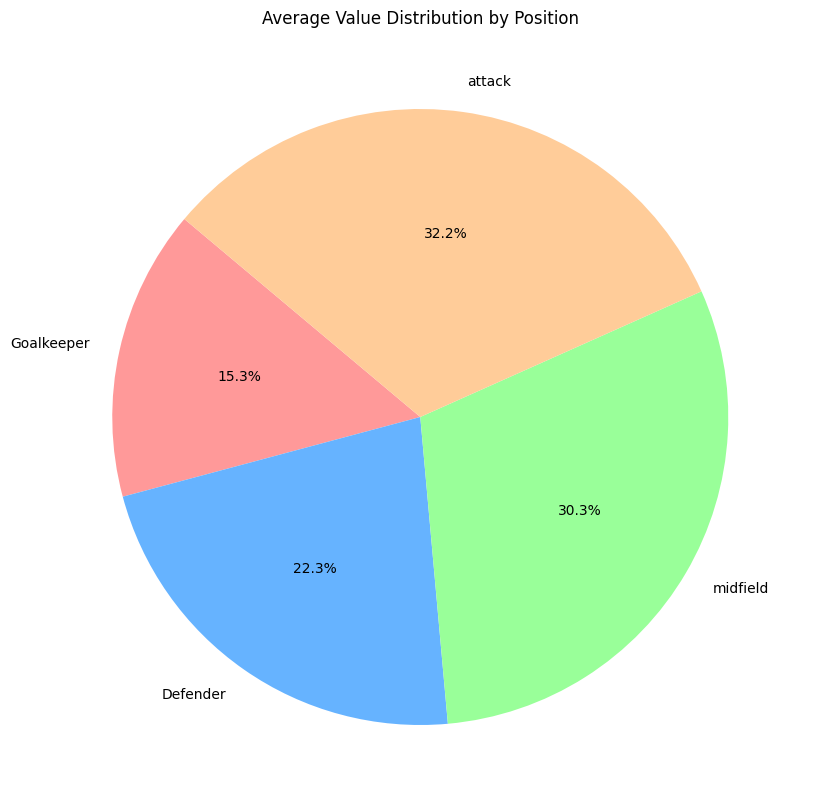

In [13]:
import matplotlib.pyplot as plt

# Calculate the average value by position
avg_value_by_position = FinalPlayerData.groupby('Position')['Value'].mean().sort_values()

# Define a custom color palette
custom_colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99', '#c2c2f0', '#ffb3e6']

# Create the pie chart with custom colors
plt.figure(figsize=(10, 10))
plt.pie(avg_value_by_position, labels=avg_value_by_position.index, autopct='%1.1f%%', startangle=140, colors=custom_colors)

# Add a title
plt.title('Average Value Distribution by Position')

# Display the pie chart
plt.show()


<ipython-input-14-cde166324d1b>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=testDATA, x='Age Group', y='Value', palette=palette)
<ipython-input-14-cde166324d1b>:13: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.boxplot(data=testDATA, x='Age Group', y='Value', palette=palette)


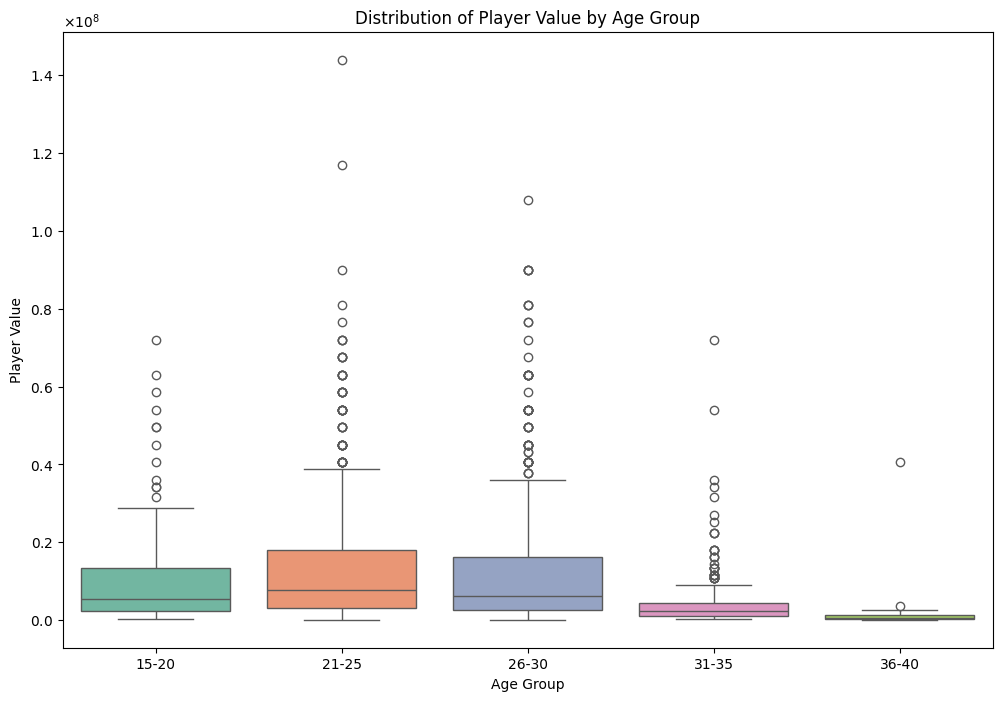

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Creating the age groups
testDATA = FinalPlayerData.copy()
testDATA['Age Group'] = pd.cut(testDATA['Age'], bins=[15, 20, 25, 30, 35, 40], labels=['15-20', '21-25', '26-30', '31-35', '36-40'])

# Define a color palette
palette = sns.color_palette("Set2", len(testDATA['Age Group'].unique()))

# Plotting the box plot with different colors for each box
plt.figure(figsize=(12, 8))
sns.boxplot(data=testDATA, x='Age Group', y='Value', palette=palette)

# Adding title and labels
plt.title('Distribution of Player Value by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Player Value')

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

plt.show()

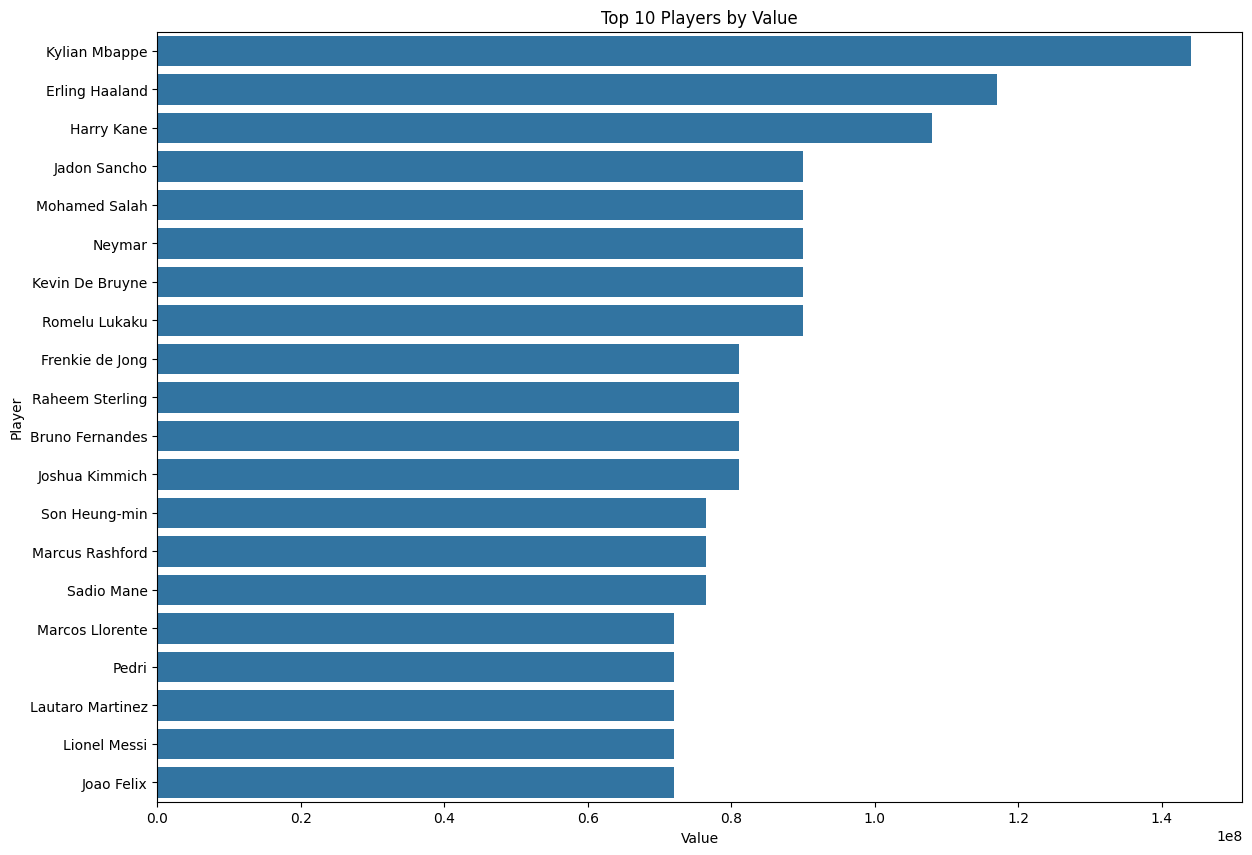

In [15]:
#Top 20 Players by Value
plt.figure(figsize=(14, 10))
top_players_by_value = FinalPlayerData[['Player', 'Value']].sort_values(by='Value', ascending=False).head(20)
sns.barplot(y=top_players_by_value['Player'], x=top_players_by_value['Value'])
plt.title('Top 10 Players by Value')
plt.xlabel('Value')
plt.ylabel('Player')
plt.show()

<Figure size 1400x1000 with 0 Axes>

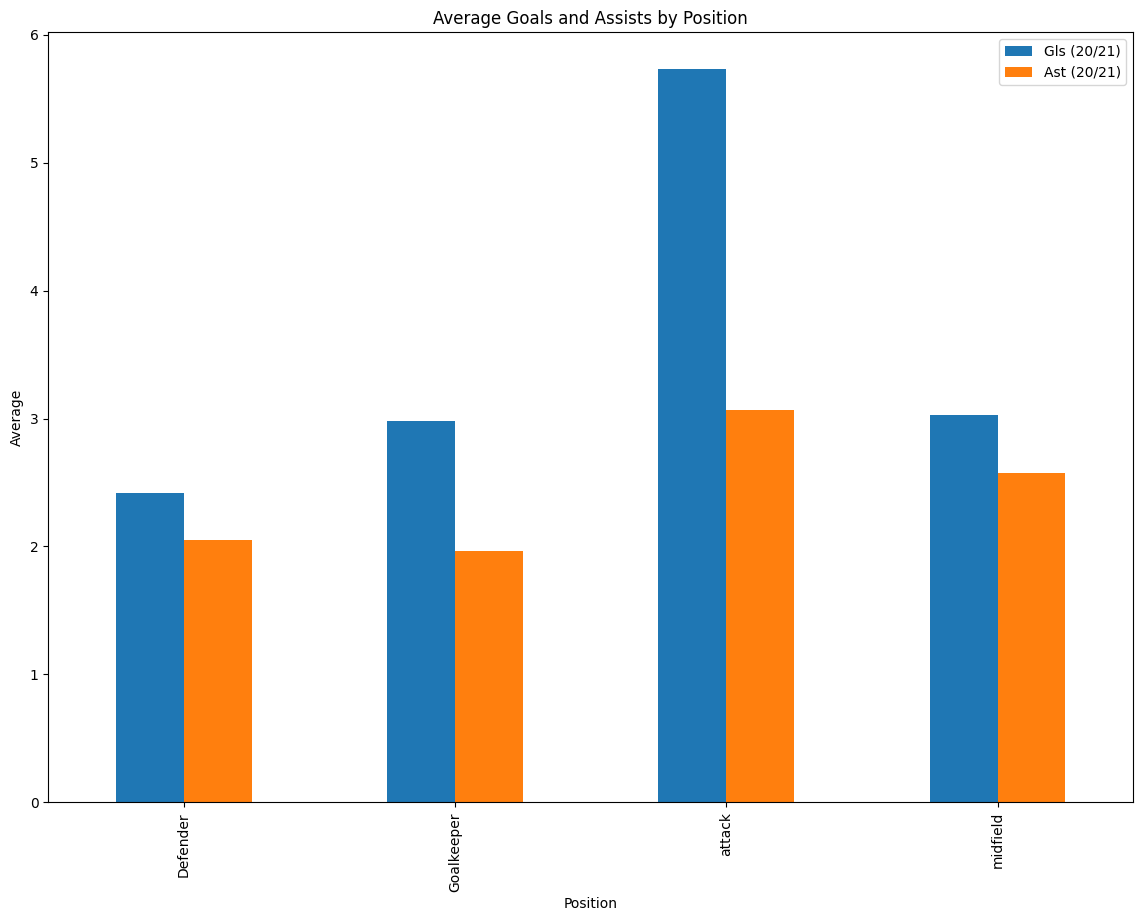

In [16]:
#Average Goals and Assists by Position
plt.figure(figsize=(14, 10))
avg_goals_assists_by_position = FinalPlayerData.groupby('Position')[['Gls (20/21)', 'Ast (20/21)']].mean()
avg_goals_assists_by_position.plot(kind='bar', figsize=(14, 10))
plt.title('Average Goals and Assists by Position')
plt.xlabel('Position')
plt.ylabel('Average')
plt.show()

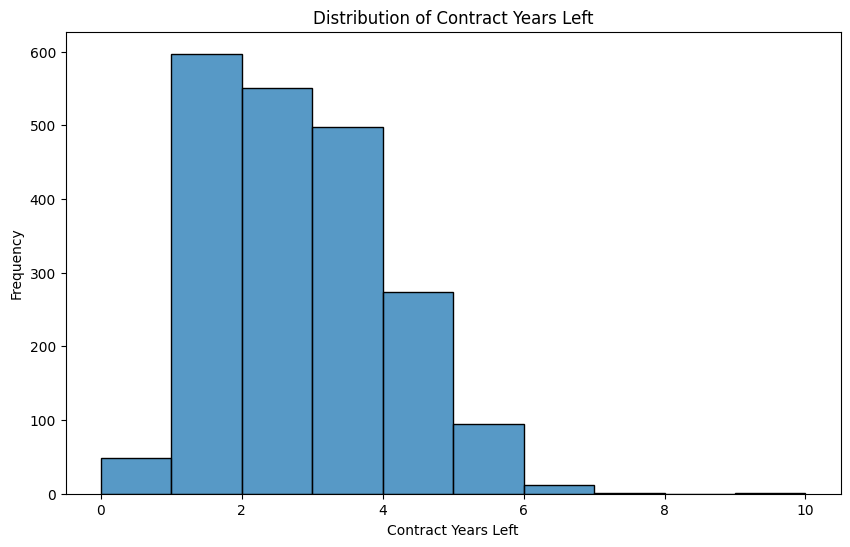

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert 'Contract Years Left' to numeric if it's not already and sort the data
testDATA['Contract Years Left'] = pd.to_numeric(testDATA['Contract Years Left'], errors='coerce')

# Sort the data based on 'Contract Years Left'
sorted_data = testDATA.sort_values(by='Contract Years Left')

# Plot the histogram with sorted data
plt.figure(figsize=(10, 6))
sns.histplot(sorted_data['Contract Years Left'], bins=10)
plt.title('Distribution of Contract Years Left')
plt.xlabel('Contract Years Left')
plt.ylabel('Frequency')
plt.show()

In [18]:
# Calculate consistency metrics
metrics = ['MP', 'Starts', 'Min', 'Total Mins/90','Gls','Ast', 'Non-Penalty Goals', 'Penalties Scored', 'Penalties Attempted', 'Yellow Cards', 'Red Cards', 'Gls/90', 'Ast/90',
           '(G+A)/90', 'Non-Penalty Goals/90', '(Gls+Ast-Scored Penalties)/90', 'xG', 'Non-Penalty xG', 'xA', 'Non-penalty xG+ xA', 'xG/90', 'xA/90', '(xG+xA)/90',
           'Non-Penalty xG/90', '(Non-Penalty xG+xA)/90', 'Total Shots', 'Total Shots on Target', 'Shots on Target%', 'Shots/90', 'Shots on Target/90', 'Goals/Shots',
           'Goals/Shots on Target', 'Avg Shot Distance (yds)', 'Freekick Shots', 'Non-Penalty xG/Shots', 'Goals Scored minus xG', 'Non-Penalty Goals Scored minus Non-Penalty xG',
           'Shot-Creating Actions', 'Shot-Creating Actions/90', 'Passes Leading to Shot Attempt', 'Set-Piece Leading to Shot Attempt', 'Dribbles Leading to Shot Attempt',
           'Shots Leading to Shot Attempt', 'Fouls Drawn Leading to Shot Attempt', 'Defensive Actions Leading to Shot Attempt', 'Goal Creating Actions', 'Goal Creating Actions/90',
           'Passes Leading to Goals', 'Set-Piece Leading to Goals', 'Dribbles Leading to Goals', 'Shots Leading to Goals', 'Fouls Drawn Leading to Goals',
           'Defensive Actions Leading to Goals', 'Touches', 'Touches in Defensive Penalty Box', 'Touches in Defensive 3rd', 'Touches in Midfield 3rd', 'Touches in Attacking 3rd',
           'Touches in Attacking Penalty Box', 'Touches in Open-play', 'Total Successful Dribbles', 'Total Attempted Dribbles', 'Dribble Success %',
           'Total no. of Players Dribbles Past', 'Total Nutmegs', 'Total Carries', 'Total Distance Carried the Ball', 'Total Distance Carried the Ball in Forward Direction',
           'Total Carries in Forward Direction', 'Carries into Final Third', 'Carries into Attacking Penalty Box', 'Total Failed Attempts at Controlling Ball',
           'Number of Times Tackled when Dribbling', 'Number of Times Player was Pass Target', 'Number of Times Received Pass', '% of Times Successfully Received Pass',
           'Progressive Passes Received', 'Passes Completed (All pass-types)', 'Passes Attempted (All pass-types)', 'Pass Completion % (All pass-types)',
           'Total Distance of Completed Passes (All Pass-types)', 'Total Distance of Completed Progressive Passes (All Pass-types)', 'Passes Completed (Short Passes)',
           'Passes Attempted (Short Passes)', 'Pass Completion % (Short Passes)', 'Passes Completed (Medium Passes)', 'Passes Attempted (Medium Passes)',
           'Pass Completion % (Medium Passes)', 'Passes Completed (Long Passes)', 'Passes Attempted (Long Passes)', 'Pass Completion % (Long Passes)', 'Total Assists',
           'xG Assisted', 'Assist minus xG Assisted', 'Completed passes that enter Final 3rd', 'Completed passes that enter Penalty Box', 'Completed Crosses that enter Penalty Box',
           'Total Completed Progressive Passes', 'Total Number of Players Tackled', 'Total Tackles Won', 'Tackles in Defensive 3rd', 'Tackles in Midfield 3rd',
           'Tackles in Attacking 3rd', 'Number of Dribblers Tackled', 'Times Dribbled Past + Total Tackles', '% of Dribblers Tackled', 'Number of Times Dribbled Past',
           'Number of Pressing Actions', 'Times Squad gained Possession within 5 seconds of Pressing Actions', 'Successful Pressure %', 'Number of Presses in Defensive Third',
           'Number of Presses in Midfield Third', 'Number of Presses in Attacking Third', 'Total Defensive Blocks', 'Total Shots Blocked', 'Goal Saving Blocks',
           'Times blocked a Pass', 'Total Interceptions', 'Total Players Tackled + Total Interceptions', 'Total Clearances', 'Mistakes leading to Opponent Shots', '2nd Yellow Cards',
           'Fouls Committed', 'Fouls Drawn', 'Offsides', 'Crosses', 'Interceptions', 'Penalty Kicks Won', 'Penalties Conceded', 'Own Goals', 'Total Loose Balls Recovered',
           'Aerial Duel Won', 'Aerial Duel Lost', '% Aerial Duels Won']
consistency_data = {'Player': FinalPlayerData['Player']}

for metric in metrics:
    consistency_data[f'{metric}_Mean'] = FinalPlayerData[[f'{metric} (20/21)', f'{metric} (19/20)', f'{metric} (18/19)', f'{metric} (17/18)']].mean(axis=1)
    consistency_data[f'{metric}_Std_Dev'] = FinalPlayerData[[f'{metric} (20/21)', f'{metric} (19/20)', f'{metric} (18/19)', f'{metric} (17/18)']].std(axis=1)
    consistency_data[f'{metric}_CV'] = (consistency_data[f'{metric}_Std_Dev'] / consistency_data[f'{metric}_Mean']) * 100

# Create a DataFrame for consistency data
consistency_dataset = pd.DataFrame(consistency_data)

# Save the dataframe to a CSV file
consistency_dataset.to_csv('gdrive/MyDrive/./Dissertation/Datasets/player_consistency_dataset.csv', index=False)

In [19]:
consistency_dataset_missing_values = consistency_dataset.isnull().sum()
print("Missing values in consistency dataset:")
print(consistency_dataset_missing_values[consistency_dataset_missing_values > 0])

Missing values in consistency dataset:
Series([], dtype: int64)


In [20]:
# Ensure that only numeric columns are checked for infinite values
numeric_cols = consistency_dataset.select_dtypes(include=[np.number]).columns

# Check for np.inf and -np.inf values
inf_columns = consistency_dataset[numeric_cols].apply(lambda col: np.isinf(col).any())
inf_columns = inf_columns[inf_columns].index.tolist()

if inf_columns:
    print(f"Columns with infinite values: {inf_columns}")
else:
    print("No columns with infinite values found.")

Columns with infinite values: ['Goals Scored minus xG_CV', 'Non-Penalty Goals Scored minus Non-Penalty xG_CV', 'Assist minus xG Assisted_CV']


In [21]:
# Replace infinite values with zero
consistency_dataset.replace([np.inf, -np.inf], 0, inplace=True)

In [22]:
# Plot the distribution of CVs for each metric
fig, axs = plt.subplots(45, 3, figsize=(40, 100))
axs = axs.flatten()
for i, metric in enumerate(metrics):
    axs[i].hist(consistency_dataset[f'{metric}_CV'], bins=25, edgecolor='k', alpha=0.7)
    axs[i].set_title(f'{metric} CV Distribution')
    axs[i].set_xlabel('Coefficient of Variation (%)')
    axs[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [23]:
# Display summary statistics for CVs
cv_summary = consistency_dataset[[f'{metric}_CV' for metric in metrics]].describe()
print(cv_summary)
# Save the summary statistics to a CSV file
cv_summary.to_csv('gdrive/MyDrive/./Dissertation/Datasets/player_cv_summary.csv', index=True)

            MP_CV  Starts_CV      Min_CV  Total Mins/90_CV      Gls_CV  \
count      2075.0     2075.0      2075.0            2075.0      2075.0   
mean    30.875474  39.521445   39.302294         39.113776   38.310466   
std     20.639796  23.138553   23.126194         23.016501   21.889954   
min           0.0   1.481481    1.362342          1.351502         0.0   
25%     15.384615  21.633937   21.008322         20.803177   13.333333   
50%     25.310765  35.625224   34.990493         34.779066   40.824829   
75%     43.579045   54.69213   54.495183         54.277418   53.924957   
max    127.179042   139.2192  147.419577        147.103668  119.499284   

           Ast_CV  Non-Penalty Goals_CV  Penalties Scored_CV  \
count      2075.0                2075.0               2075.0   
mean    38.215586             37.883661             5.786191   
std     17.182297             20.340881            15.479278   
min           0.0                   0.0                  0.0   
25%     23.09

In [24]:
thresholds = {}
for i, metric in enumerate(metrics):
  thresholds[metric] = np.percentile(consistency_dataset[f'{metric}_CV'], 75)  # 75th percentile as threshold
print(f'Chosen Consistency Thresholds (75th percentile): {thresholds}')

Chosen Consistency Thresholds (75th percentile): {'MP': 43.579044606400224, 'Starts': 54.69212960916432, 'Min': 54.495182875952636, 'Total Mins/90': 54.277417938584705, 'Gls': 53.92495694393378, 'Ast': 46.15384615384615, 'Non-Penalty Goals': 51.63977794943222, 'Penalties Scored': 0.0, 'Penalties Attempted': 0.0, 'Yellow Cards': 52.54846546645948, 'Red Cards': 0.0, 'Gls/90': 54.56462908034828, 'Ast/90': 49.481831319229805, '(G+A)/90': 56.03754346197573, 'Non-Penalty Goals/90': 53.78728939305343, '(Gls+Ast-Scored Penalties)/90': 55.94787645527158, 'xG': 69.28441349660494, 'Non-Penalty xG': 68.22633177256446, 'xA': 67.3585724487344, 'Non-penalty xG+ xA': 65.4601009132184, 'xG/90': 63.37592298118297, 'xA/90': 58.892602543389366, '(xG+xA)/90': 57.600120338486754, 'Non-Penalty xG/90': 62.06612730032945, '(Non-Penalty xG+xA)/90': 56.35999571706513, 'Total Shots': 62.450276597645114, 'Total Shots on Target': 60.85806194501846, 'Shots on Target%': 34.36283810775347, 'Shots/90': 51.1996364326555

In [25]:
# Determine consistency for each player
def is_consistent(row):
    consistent_features = sum(row[f'{metric}_CV'] < thresholds[metric] for metric in metrics)
    # Flexible Aggregation: Player is consistent if they are consistent in at least 75% of the metrics; total length 100 and req 100
    required_consistent_metrics = int(len(metrics) * 0.70)
    return 'Consistent' if consistent_features >= required_consistent_metrics else 'Inconsistent'

consistency_dataset['Consistency_Label'] = consistency_dataset.apply(is_consistent, axis=1)

# Save the dataframe to a CSV file
consistency_dataset.to_csv('gdrive/MyDrive/./Dissertation/Datasets/player_consistency_dataset.csv', index=False)

In [26]:
# Count the number of consistent and non-consistent players
consistency_counts = consistency_dataset['Consistency_Label'].value_counts()
consistent_count = consistency_counts.get('Consistent', 0)
non_consistent_count = consistency_counts.get('Inconsistent', 0)

# Display the counts
print(f'Number of Consistent Players: {consistent_count}')
print(f'Number of Non-Consistent Players: {non_consistent_count}')

Number of Consistent Players: 1175
Number of Non-Consistent Players: 900


In [27]:
# Merge the DataFrames on the 'Player' column, keeping only the 'Consistency_Label' column from consistency_dataset
mergedDataset = pd.merge(FinalPlayerData, consistency_dataset[['Player', 'Consistency_Label']], on='Player', how='left')

mergedDataset.to_csv('gdrive/MyDrive/./Dissertation/Datasets/player_merged_dataset.csv', index=False)

In [28]:
print(mergedDataset.isnull().values.any())

False


In [29]:
# Specify the predictor variables and assign them to 'x_data'
# Assuming 'Consistency_Label' is the target variable and all other columns are predictors
x_data = mergedDataset.drop(['Player', 'Consistency_Label'], axis=1)

# Specify the target variable and assign it to 'y_data'
y_data = mergedDataset['Consistency_Label']

# Display the shapes of the predictor and target datasets
print("Shape of predictor dataset (x_data):", x_data.shape)
print("Shape of target dataset (y_data):", y_data.shape)

Shape of predictor dataset (x_data): (2127, 547)
Shape of target dataset (y_data): (2127,)


In [30]:
# Split the data into training (70%) and testing (30%) sets
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.3, random_state=42)

# Check the sizes of both sets
print("Size of training set (x_train):", x_train.shape)
print("Size of testing set (x_test):", x_test.shape)
print("Size of training target (y_train):", y_train.shape)
print("Size of testing target (y_test):", y_test.shape)

Size of training set (x_train): (1488, 547)
Size of testing set (x_test): (639, 547)
Size of training target (y_train): (1488,)
Size of testing target (y_test): (639,)


In [31]:
def compute_performance(y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred, average='macro')
    precision = precision_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    cr = classification_report(y_test, y_pred)
    return accuracy, recall, precision, f1, cm, cr

In [32]:
def train_decision_tree_classifier(x_train, y_train):
    # Identify numerical and categorical features
    numerical_features = x_train.select_dtypes(include=['int64', 'float64']).columns
    categorical_features = x_train.select_dtypes(include=['object']).columns

    # Create a column transformer to preprocess numerical and categorical data
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ])

    # Create a pipeline with the preprocessor and the DecisionTreeClassifier
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('decision_tree', DecisionTreeClassifier(random_state=0))
    ])

    # Define hyperparameters to tune
    param_grid = {
        'decision_tree__max_depth': [None, 5, 10, 15, 20, 25, 30, 35, 40],
        'decision_tree__min_samples_split': [2, 5, 10, 15, 20, 25],
        'decision_tree__min_samples_leaf': [1, 2, 5, 10, 15],
        'decision_tree__max_features': [None, 'sqrt', 'log2'],
        'decision_tree__min_impurity_decrease': [0.0, 0.01, 0.05, 0.1],
        'decision_tree__class_weight': [None, 'balanced'],
        'decision_tree__min_weight_fraction_leaf': [0.0, 0.01, 0.05]
    }

    # Use RandomizedSearchCV to find the best hyperparameters
    randomized_search = RandomizedSearchCV(
        pipeline, param_distributions=param_grid,
        n_iter=100,  # Increase the number of iterations to search more combinations
        cv=3, scoring='accuracy', random_state=0, n_jobs=-1,
        verbose=1  # Added verbosity to track the progress
    )
    randomized_search.fit(x_train, y_train)

    # Print the best parameters and the best score
    print("Best Parameters:", randomized_search.best_params_)
    print("Best Cross-Validation Score:", randomized_search.best_score_)

    # Return the best model
    best_model = randomized_search.best_estimator_

    return best_model


In [33]:
def test_decision_tree_classifier(model, x_test):
    # Predict on the testing set
    y_pred = model.predict(x_test)
    return y_pred

In [34]:
# Train the model and get the best model
decision_tree_classifier_best_model = train_decision_tree_classifier(x_train, y_train)

# Test the model
y_pred_decision_tree = test_decision_tree_classifier(decision_tree_classifier_best_model, x_test)

# Compute performance metrics
accuracy_decision_tree, recall_decision_tree, precision_decision_tree, f1_decision_tree, cm_decision_tree, cr_decision_tree= compute_performance(y_test, y_pred_decision_tree)
print(f"Accuracy: {accuracy_decision_tree}")
print(f"Recall (macro): {recall_decision_tree}")
print(f"Precision (macro): {precision_decision_tree}")
print(f"F1 Score (macro): {f1_decision_tree}")
print(f"Confusion Matrix:\n{cm_decision_tree}")
print(f"Decision Tree Classification Report:\n {cr_decision_tree}")

# Metrics for each model
accuracy.append(accuracy_decision_tree)
recall.append(recall_decision_tree)
precision.append(precision_decision_tree)
f1score.append(f1_decision_tree)


Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'decision_tree__min_weight_fraction_leaf': 0.0, 'decision_tree__min_samples_split': 10, 'decision_tree__min_samples_leaf': 1, 'decision_tree__min_impurity_decrease': 0.01, 'decision_tree__max_features': None, 'decision_tree__max_depth': 40, 'decision_tree__class_weight': None}
Best Cross-Validation Score: 0.7809139784946236
Accuracy: 0.7574334898278561
Recall (macro): 0.7472120612951063
Precision (macro): 0.7629168944778568
F1 Score (macro): 0.7494593056346044
Confusion Matrix:
[[299  51]
 [104 185]]
Decision Tree Classification Report:
               precision    recall  f1-score   support

  Consistent       0.74      0.85      0.79       350
Inconsistent       0.78      0.64      0.70       289

    accuracy                           0.76       639
   macro avg       0.76      0.75      0.75       639
weighted avg       0.76      0.76      0.75       639



In [35]:
comparison_decision_tree_classifier = pd.DataFrame({
    'Actual Consistency Label': y_test,
    'Predicted Consistency Label': y_pred_decision_tree
})

# Display the comparison
print("\nComparison of Actual Consistency Label and Predicted Consistency Label:")
print(comparison_decision_tree_classifier.head(20))


Comparison of Actual Consistency Label and Predicted Consistency Label:
     Actual Consistency Label Predicted Consistency Label
282              Inconsistent                  Consistent
1999               Consistent                  Consistent
1709             Inconsistent                  Consistent
988                Consistent                  Consistent
2018             Inconsistent                Inconsistent
297                Consistent                  Consistent
1737             Inconsistent                Inconsistent
651                Consistent                  Consistent
70                 Consistent                  Consistent
290                Consistent                  Consistent
1713               Consistent                Inconsistent
1951             Inconsistent                  Consistent
507                Consistent                  Consistent
1376             Inconsistent                  Consistent
914                Consistent                  Consistent

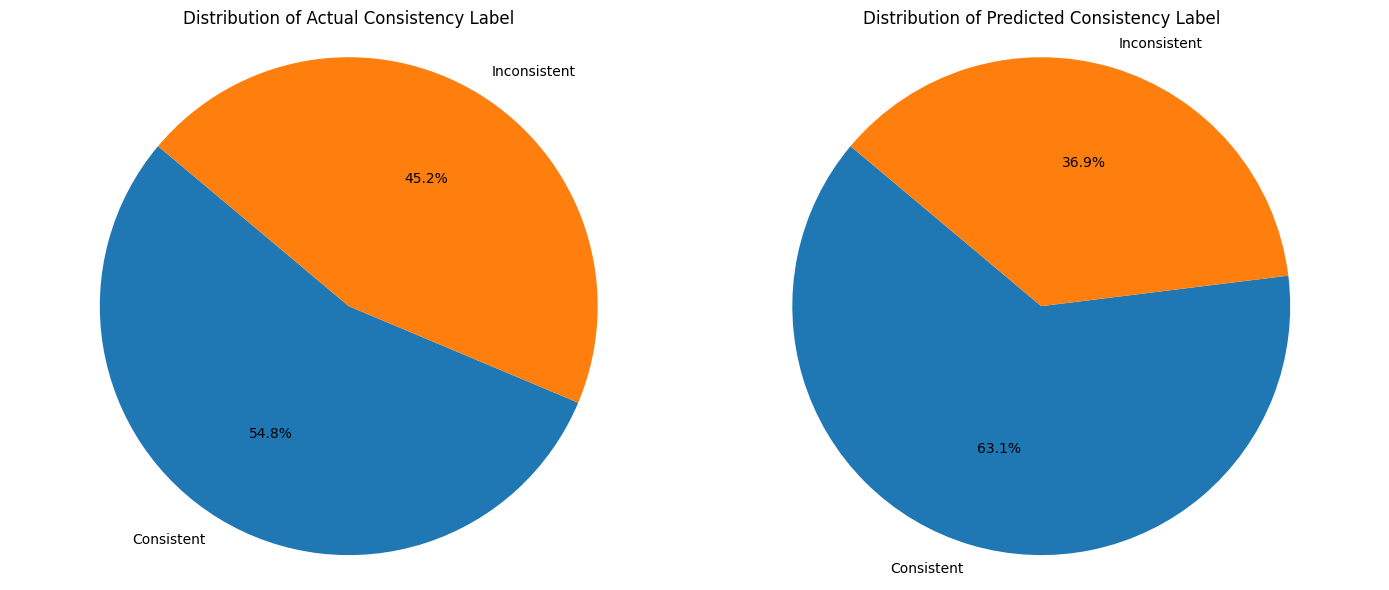

In [36]:
# Get the value counts for actual and predicted labels
actual_counts_deci_tree = comparison_decision_tree_classifier['Actual Consistency Label'].value_counts()
predicted_counts_deci_tree = comparison_decision_tree_classifier['Predicted Consistency Label'].value_counts()

# Create a figure with two subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot pie chart for Actual Consistency Label
axs[0].pie(actual_counts_deci_tree.values, labels=actual_counts_deci_tree.index, autopct='%1.1f%%', startangle=140)
axs[0].set_title('Distribution of Actual Consistency Label')
axs[0].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Plot pie chart for Predicted Consistency Label
axs[1].pie(predicted_counts_deci_tree.values, labels=predicted_counts_deci_tree.index, autopct='%1.1f%%', startangle=140)
axs[1].set_title('Distribution of Predicted Consistency Label')
axs[1].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Adjust layout to ensure the plots are side by side
plt.tight_layout()
plt.show()

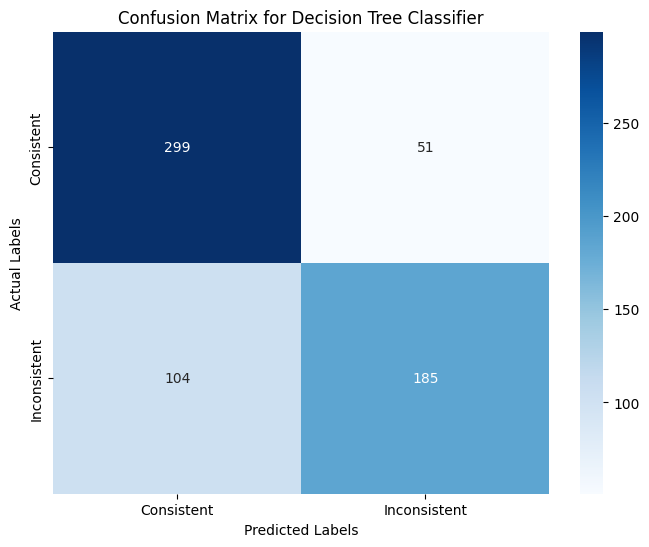

In [37]:
# Confusion matrix
deci_tree_conf_matrix = confusion_matrix(comparison_decision_tree_classifier['Actual Consistency Label'],
                               comparison_decision_tree_classifier['Predicted Consistency Label'],
                               labels=['Consistent', 'Inconsistent'])

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(deci_tree_conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Consistent', 'Inconsistent'], yticklabels=['Consistent', 'Inconsistent'])
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix for Decision Tree Classifier')
plt.show()

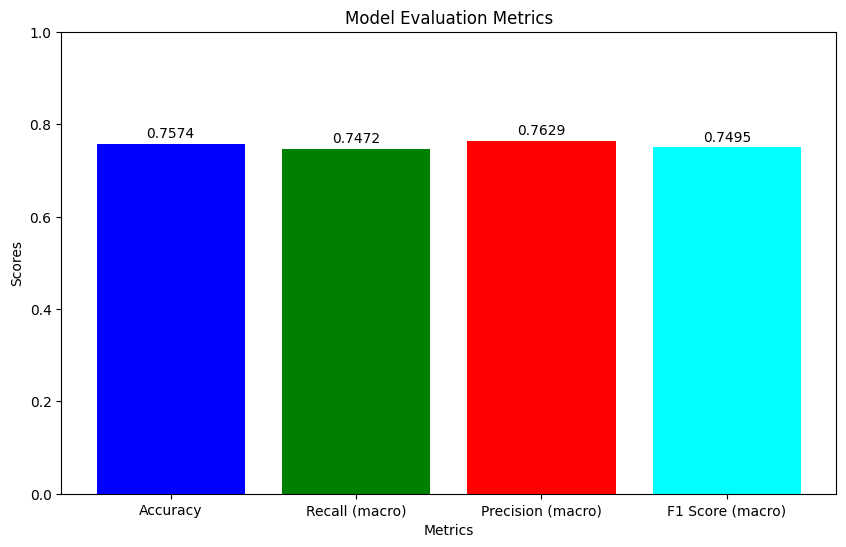

In [38]:
# Metrics dictionary for plotting
metrics = {
    'Accuracy': accuracy_decision_tree,
    'Recall (macro)': recall_decision_tree,
    'Precision (macro)': precision_decision_tree,
    'F1 Score (macro)': f1_decision_tree
}

# Plotting the metrics
fig, ax = plt.subplots(figsize=(10, 6))

# X-axis: Metrics, Y-axis: Values
metric_names = list(metrics.keys())
metric_values = list(metrics.values())

# Bar plot
bars = ax.bar(metric_names, metric_values, color=['blue', 'green', 'red', 'cyan', 'magenta'])

# Adding the metric values on top of each bar
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height * 1.01, f'{height:.4f}', ha='center', va='bottom')

# Adding titles and labels
plt.title('Model Evaluation Metrics')
plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Setting y-axis limits to 0-1 for better visualization

plt.show()




In [39]:
def train_random_forest_classifier(x_train, y_train):
    # Identify numerical and categorical features
    numerical_features = x_train.select_dtypes(include=['int64', 'float64']).columns
    categorical_features = x_train.select_dtypes(include=['object']).columns

    # Create a column transformer to preprocess numerical and categorical data
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ])

    # Create a pipeline with the preprocessor and the RandomForestClassifier
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('random_forest', RandomForestClassifier(random_state=0))
    ])

    # Define hyperparameters to tune (with more constrained ranges)
    param_grid = {
        'random_forest__n_estimators': [50, 100],  # Fewer trees
        'random_forest__max_depth': [10, 15, 20],  # Reduced max depth
        'random_forest__min_samples_split': [10, 15],  # Larger min samples to split
        'random_forest__min_samples_leaf': [4, 6],  # Larger min samples per leaf
        'random_forest__max_features': ['sqrt'],  # Default behavior for max features
        'random_forest__bootstrap': [True]  # Use bootstrap sampling
    }

    # Use RandomizedSearchCV to find the best hyperparameters
    randomized_search = RandomizedSearchCV(pipeline, param_grid, n_iter=30, cv=3, scoring='accuracy', random_state=0, n_jobs=-1)
    randomized_search.fit(x_train, y_train)

    # Print the best parameters and the best score
    print("Best Parameters:", randomized_search.best_params_)
    print("Best Cross-Validation Score:", randomized_search.best_score_)

    # Return the best model
    best_model = randomized_search.best_estimator_
    return best_model

In [40]:
def test_random_forest_classifier(model, x_test):
    # Predict on the testing set
    y_pred = model.predict(x_test)
    return y_pred

In [41]:
# Train the model and get the best model
random_forest_classifier_best_model = train_random_forest_classifier(x_train, y_train)

# Test the model
y_pred_random_forest = test_random_forest_classifier(random_forest_classifier_best_model, x_test)

# Compute performance metrics
accuracy_random_forest, recall_random_forest, precision_random_forest, f1_random_forest, cm_random_forest, cr_random_forest= compute_performance(y_test, y_pred_random_forest)
print(f"Accuracy: {accuracy_random_forest}")
print(f"Recall (macro): {recall_random_forest}")
print(f"Precision (macro): {precision_random_forest}")
print(f"F1 Score (macro): {f1_random_forest}")
print(f"Confusion Matrix:\n{cm_random_forest}")
print(f"Random Forest Classification Report:\n {cr_random_forest}")

# Metrics for each model
accuracy.append(accuracy_random_forest)
recall.append(recall_random_forest)
precision.append(precision_random_forest)
f1score.append(f1_random_forest)

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_search.py:307: UserWarning: The total space of parameters 24 is smaller than n_iter=30. Running 24 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best Parameters: {'random_forest__n_estimators': 100, 'random_forest__min_samples_split': 10, 'random_forest__min_samples_leaf': 6, 'random_forest__max_features': 'sqrt', 'random_forest__max_depth': 10, 'random_forest__bootstrap': True}
Best Cross-Validation Score: 0.8434139784946236
Accuracy: 0.8497652582159625
Recall (macro): 0.845971329708354
Precision (macro): 0.8502371944994895
F1 Score (macro): 0.8475516411857095
Confusion Matrix:
[[310  40]
 [ 56 233]]
Random Forest Classification Report:
               precision    recall  f1-score   support

  Consistent       0.85      0.89      0.87       350
Inconsistent       0.85      0.81      0.83       289

    accuracy                           0.85       639
   macro avg       0.85      0.85      0.85       639
weighted avg       0.85      0.85      0.85       639



In [42]:
comparison_random_forest_classifier = pd.DataFrame({
    'Actual Consistency Label': y_test,
    'Predicted Consistency Label': y_pred_random_forest
})

# Display the comparison
print("\nComparison of Actual Consistency Label and Predicted Consistency Label:")
print(comparison_random_forest_classifier.head(20))


Comparison of Actual Consistency Label and Predicted Consistency Label:
     Actual Consistency Label Predicted Consistency Label
282              Inconsistent                Inconsistent
1999               Consistent                  Consistent
1709             Inconsistent                Inconsistent
988                Consistent                  Consistent
2018             Inconsistent                Inconsistent
297                Consistent                  Consistent
1737             Inconsistent                Inconsistent
651                Consistent                  Consistent
70                 Consistent                  Consistent
290                Consistent                  Consistent
1713               Consistent                Inconsistent
1951             Inconsistent                Inconsistent
507                Consistent                  Consistent
1376             Inconsistent                Inconsistent
914                Consistent                  Consistent

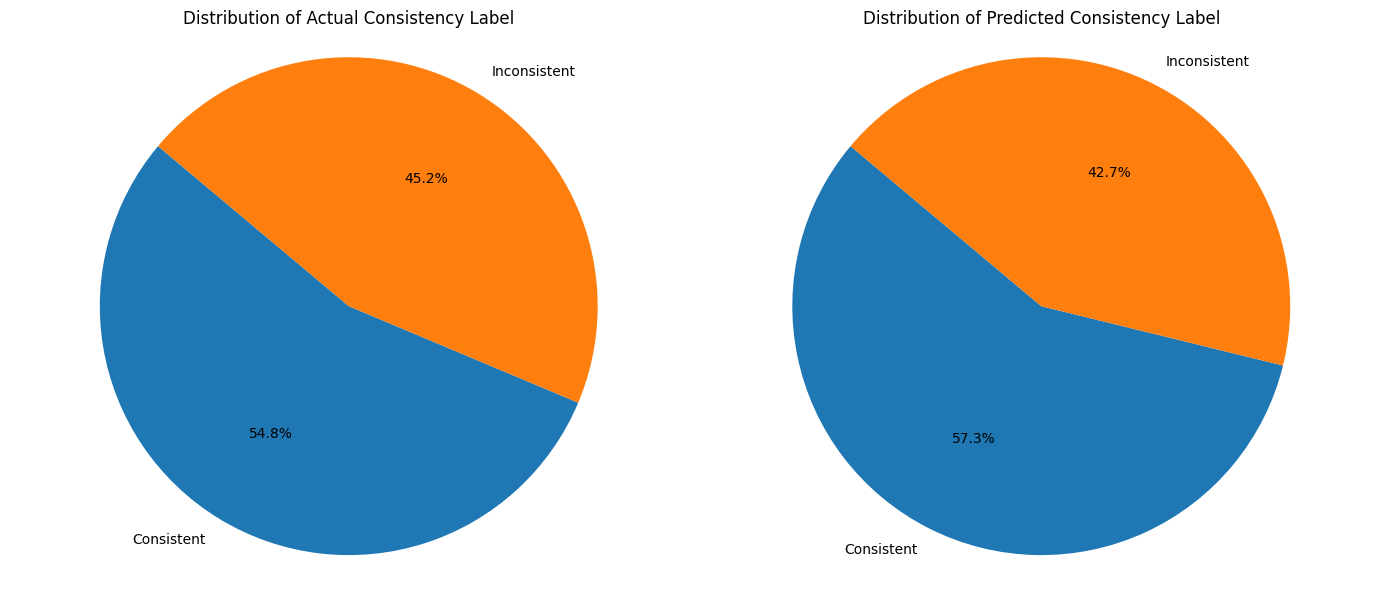

In [43]:
# Get the value counts for actual and predicted labels
actual_counts_ran_for = comparison_random_forest_classifier['Actual Consistency Label'].value_counts()
predicted_counts_ran_for = comparison_random_forest_classifier['Predicted Consistency Label'].value_counts()

# Create a figure with two subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot pie chart for Actual Consistency Label
axs[0].pie(actual_counts_ran_for.values, labels=actual_counts_ran_for.index, autopct='%1.1f%%', startangle=140)
axs[0].set_title('Distribution of Actual Consistency Label')
axs[0].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Plot pie chart for Predicted Consistency Label
axs[1].pie(predicted_counts_ran_for.values, labels=predicted_counts_ran_for.index, autopct='%1.1f%%', startangle=140)
axs[1].set_title('Distribution of Predicted Consistency Label')
axs[1].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Adjust layout to ensure the plots are side by side
plt.tight_layout()
plt.show()

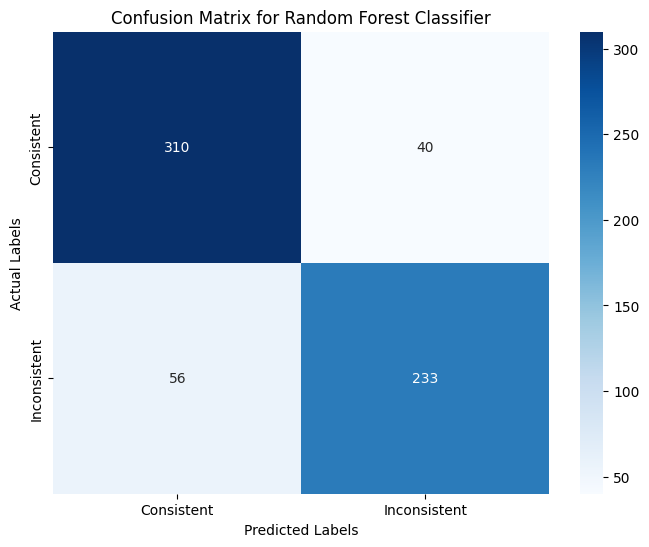

In [44]:
# Confusion matrix
rand_for_conf_matrix = confusion_matrix(comparison_random_forest_classifier['Actual Consistency Label'],
                               comparison_random_forest_classifier['Predicted Consistency Label'],
                               labels=['Consistent', 'Inconsistent'])

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(rand_for_conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Consistent', 'Inconsistent'], yticklabels=['Consistent', 'Inconsistent'])
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix for Random Forest Classifier')
plt.show()

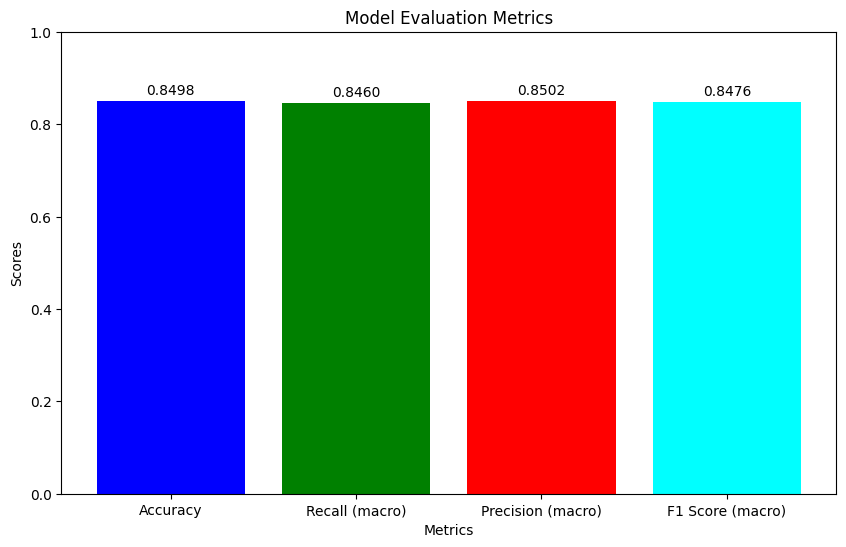

In [45]:
# Metrics dictionary for plotting
metrics = {
    'Accuracy': accuracy_random_forest,
    'Recall (macro)': recall_random_forest,
    'Precision (macro)': precision_random_forest,
    'F1 Score (macro)': f1_random_forest
}

# Plotting the metrics
fig, ax = plt.subplots(figsize=(10, 6))

# X-axis: Metrics, Y-axis: Values
metric_names = list(metrics.keys())
metric_values = list(metrics.values())

# Bar plot
bars = ax.bar(metric_names, metric_values, color=['blue', 'green', 'red', 'cyan', 'magenta'])

# Adding the metric values on top of each bar
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height * 1.01, f'{height:.4f}', ha='center', va='bottom')

# Adding titles and labels
plt.title('Model Evaluation Metrics')
plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Setting y-axis limits to 0-1 for better visualization

plt.show()




In [46]:
def train_gradient_boosting_classifier(x_train, y_train):
    # Identify numerical and categorical features
    numerical_features = x_train.select_dtypes(include=['int64', 'float64']).columns
    categorical_features = x_train.select_dtypes(include=['object']).columns

    # Create a column transformer to preprocess numerical and categorical data
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ])

    # Create a pipeline with the preprocessor and the GradientBoostingClassifier
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('gradient_boosting', GradientBoostingClassifier(random_state=0))
    ])

    # Define hyperparameters to tune
    param_grid = {
        'gradient_boosting__n_estimators': [50, 100, 200],
        'gradient_boosting__learning_rate': [0.01, 0.05, 0.1, 0.2],
        'gradient_boosting__max_depth': [3, 5, 7, 10],
        'gradient_boosting__min_samples_split': [2, 5, 10],
        'gradient_boosting__min_samples_leaf': [1, 2, 4],
        'gradient_boosting__subsample': [0.6, 0.8, 1.0],
        'gradient_boosting__max_features': ['sqrt', 'log2', None]
    }

    # Use RandomizedSearchCV to find the best hyperparameters
    randomized_search = RandomizedSearchCV(pipeline, param_grid, n_iter=50, cv=3, scoring='accuracy', random_state=0, n_jobs=-1)
    randomized_search.fit(x_train, y_train)

    # Print the best parameters and the best score
    print("Best Parameters:", randomized_search.best_params_)
    print("Best Cross-Validation Score:", randomized_search.best_score_)

    # Return the best model
    best_model = randomized_search.best_estimator_
    return best_model

In [47]:
def test_gradient_boosting_classifier(model, x_test):
    # Predict on the testing set
    y_pred = model.predict(x_test)
    return y_pred

In [48]:
# Train the model and get the best model
gradient_boosting_classifier_best_model = train_gradient_boosting_classifier(x_train, y_train)

# Test the model
y_pred_gradient_boosting = test_gradient_boosting_classifier(gradient_boosting_classifier_best_model, x_test)

# Compute performance metrics
accuracy_gradient_boosting, recall_gradient_boosting, precision_gradient_boosting, f1_rgradient_boosting, cm_gradient_boosting, cr_gradient_boosting = compute_performance(y_test, y_pred_gradient_boosting)
print(f"Accuracy: {accuracy_gradient_boosting}")
print(f"Recall (macro): {recall_gradient_boosting}")
print(f"Precision (macro): {precision_gradient_boosting}")
print(f"F1 Score (macro): {f1_rgradient_boosting}")
print(f"Confusion Matrix:\n{cm_gradient_boosting}")
print(f"Gradient Boosting Classification Report:\n {cr_gradient_boosting}")

# Metrics for each model
accuracy.append(accuracy_gradient_boosting)
recall.append(recall_gradient_boosting)
precision.append(precision_gradient_boosting)
f1score.append(f1_rgradient_boosting)

Best Parameters: {'gradient_boosting__subsample': 1.0, 'gradient_boosting__n_estimators': 200, 'gradient_boosting__min_samples_split': 10, 'gradient_boosting__min_samples_leaf': 2, 'gradient_boosting__max_features': 'log2', 'gradient_boosting__max_depth': 10, 'gradient_boosting__learning_rate': 0.2}
Best Cross-Validation Score: 0.8635752688172044
Accuracy: 0.8685446009389671
Recall (macro): 0.8634157192288681
Precision (macro): 0.8717286222797508
F1 Score (macro): 0.8660618038088395
Confusion Matrix:
[[321  29]
 [ 55 234]]
Gradient Boosting Classification Report:
               precision    recall  f1-score   support

  Consistent       0.85      0.92      0.88       350
Inconsistent       0.89      0.81      0.85       289

    accuracy                           0.87       639
   macro avg       0.87      0.86      0.87       639
weighted avg       0.87      0.87      0.87       639



In [49]:
comparison_gradient_boosting_classifier = pd.DataFrame({
    'Actual Consistency Label': y_test,
    'Predicted Consistency Label': y_pred_gradient_boosting
})

# Display the comparison
print("\nComparison of Actual Consistency Label and Predicted Consistency Label:")
print(comparison_gradient_boosting_classifier.head(20))


Comparison of Actual Consistency Label and Predicted Consistency Label:
     Actual Consistency Label Predicted Consistency Label
282              Inconsistent                  Consistent
1999               Consistent                  Consistent
1709             Inconsistent                Inconsistent
988                Consistent                  Consistent
2018             Inconsistent                Inconsistent
297                Consistent                  Consistent
1737             Inconsistent                Inconsistent
651                Consistent                  Consistent
70                 Consistent                  Consistent
290                Consistent                  Consistent
1713               Consistent                Inconsistent
1951             Inconsistent                Inconsistent
507                Consistent                  Consistent
1376             Inconsistent                  Consistent
914                Consistent                  Consistent

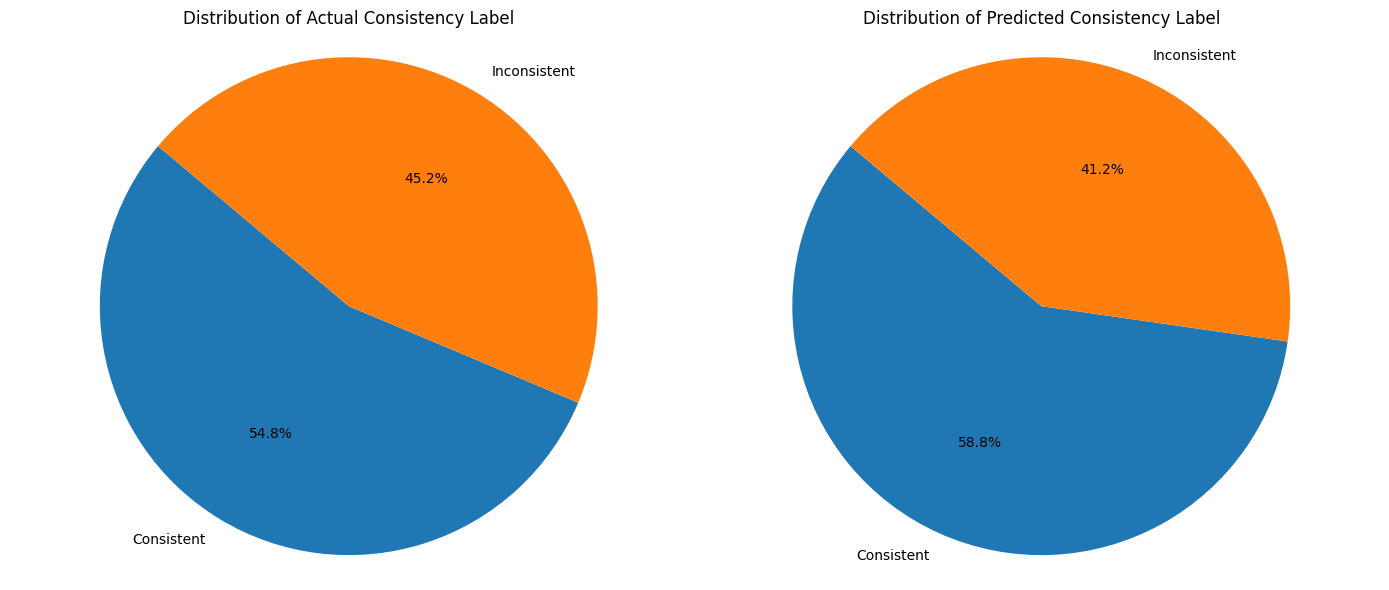

In [50]:
# Get the value counts for actual and predicted labels
actual_counts_grad_bost = comparison_gradient_boosting_classifier['Actual Consistency Label'].value_counts()
predicted_counts_grad_bost = comparison_gradient_boosting_classifier['Predicted Consistency Label'].value_counts()

# Create a figure with two subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot pie chart for Actual Consistency Label
axs[0].pie(actual_counts_grad_bost.values, labels=actual_counts_grad_bost.index, autopct='%1.1f%%', startangle=140)
axs[0].set_title('Distribution of Actual Consistency Label')
axs[0].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Plot pie chart for Predicted Consistency Label
axs[1].pie(predicted_counts_grad_bost.values, labels=predicted_counts_grad_bost.index, autopct='%1.1f%%', startangle=140)
axs[1].set_title('Distribution of Predicted Consistency Label')
axs[1].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Adjust layout to ensure the plots are side by side
plt.tight_layout()
plt.show()

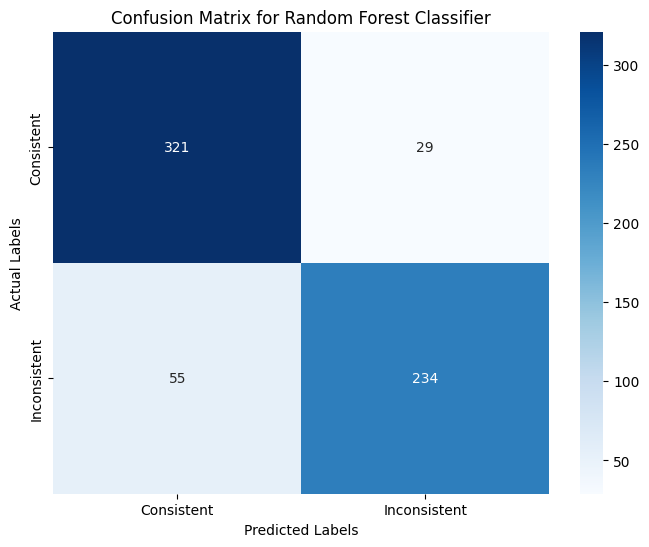

In [51]:
# Confusion matrix
xgbost_conf_matrix = confusion_matrix(comparison_gradient_boosting_classifier['Actual Consistency Label'],
                               comparison_gradient_boosting_classifier['Predicted Consistency Label'],
                               labels=['Consistent', 'Inconsistent'])

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(xgbost_conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Consistent', 'Inconsistent'], yticklabels=['Consistent', 'Inconsistent'])
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix for Random Forest Classifier')
plt.show()

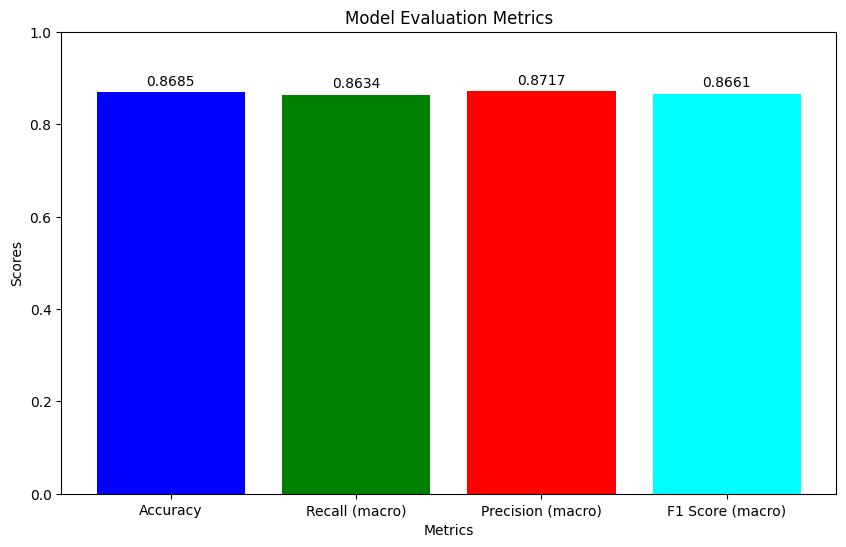

In [52]:
# Metrics dictionary for plotting
metrics = {
    'Accuracy': accuracy_gradient_boosting,
    'Recall (macro)': recall_gradient_boosting,
    'Precision (macro)': precision_gradient_boosting,
    'F1 Score (macro)': f1_rgradient_boosting
}

# Plotting the metrics
fig, ax = plt.subplots(figsize=(10, 6))

# X-axis: Metrics, Y-axis: Values
metric_names = list(metrics.keys())
metric_values = list(metrics.values())

# Bar plot
bars = ax.bar(metric_names, metric_values, color=['blue', 'green', 'red', 'cyan', 'magenta'])

# Adding the metric values on top of each bar
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height * 1.01, f'{height:.4f}', ha='center', va='bottom')

# Adding titles and labels
plt.title('Model Evaluation Metrics')
plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Setting y-axis limits to 0-1 for better visualization

plt.show()




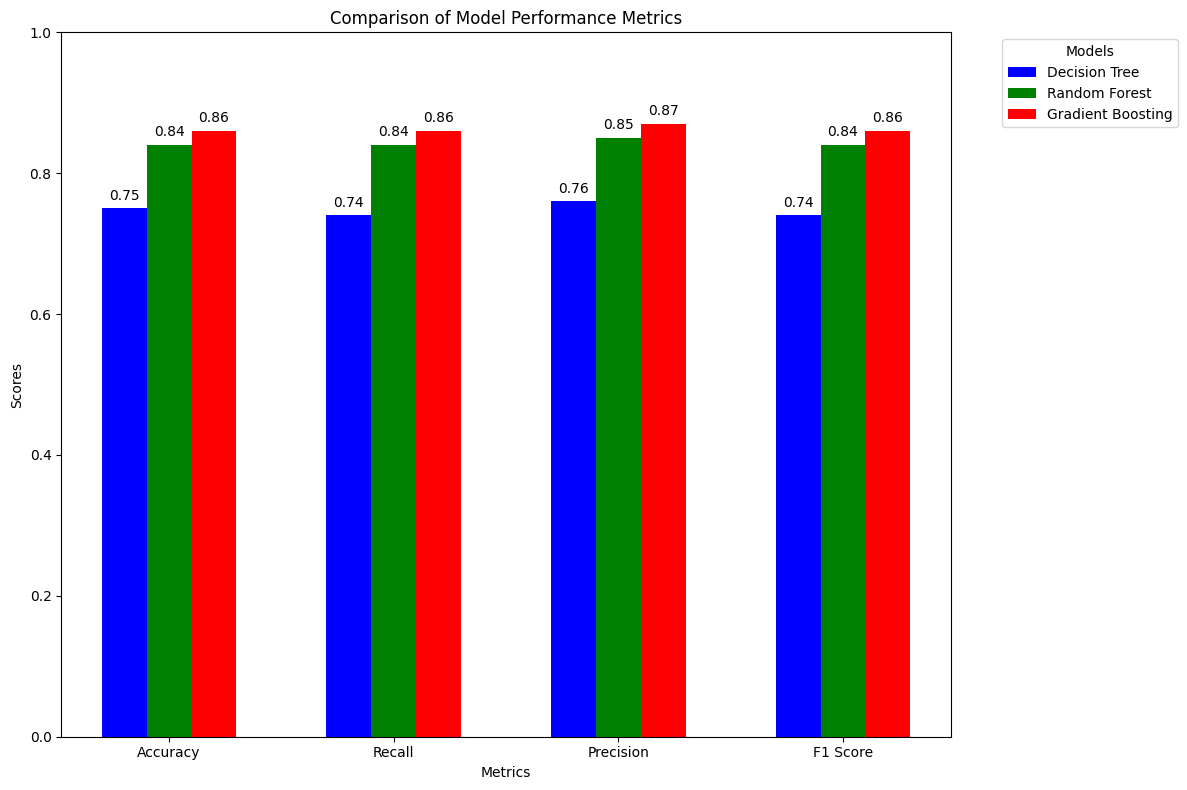

In [53]:
# Convert metrics to Decimal for precise formatting
accuracy = [Decimal(str(val)).quantize(Decimal('0.01'), rounding='ROUND_DOWN') for val in accuracy]
recall = [Decimal(str(val)).quantize(Decimal('0.01'), rounding='ROUND_DOWN') for val in recall]
precision = [Decimal(str(val)).quantize(Decimal('0.01'), rounding='ROUND_DOWN') for val in precision]
f1score = [Decimal(str(val)).quantize(Decimal('0.01'), rounding='ROUND_DOWN') for val in f1score]

# Combine the metrics into a 2D array for easier manipulation
metrics = [accuracy, recall, precision, f1score]
metric_names = ['Accuracy', 'Recall', 'Precision', 'F1 Score']

# Creating the figure and axes
fig, ax = plt.subplots(figsize=(12, 8))

# Define bar width
bar_width = 0.2

# Set positions of bars on X-axis
bar_positions = np.arange(len(metric_names))

# Create the bars for each model
models = ['Decision Tree', 'Random Forest', 'Gradient Boosting']
colors = ['blue', 'green', 'red']
for i, (model, color) in enumerate(zip(models, colors)):
    # Extract the metric values for the current model
    model_metrics = [metric[i] for metric in metrics]
    # Create bars for the current model
    bars = ax.bar(bar_positions + i * bar_width, model_metrics, bar_width, label=model, color=color)
    # Add metric values on top of each bar
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height * 1.01, f'{height}', ha='center', va='bottom')

# Setting labels, title, and legend
ax.set_xlabel('Metrics')
ax.set_ylabel('Scores')
ax.set_title('Comparison of Model Performance Metrics')
ax.set_xticks(bar_positions + bar_width)
ax.set_xticklabels(metric_names)
ax.legend(title='Models', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.ylim(0, 1)  # Setting y-axis limits to 0-1 for better visualization
plt.tight_layout()
plt.show()


In [54]:
mergedDataset.head()

,Player,Club,Age,Position,Nation,Value,Contract Years Left,League,Squad (20/21),MP (20/21),...,Crosses (17/18),Interceptions (17/18),Penalty Kicks Won (17/18),Penalties Conceded (17/18),Own Goals (17/18),Total Loose Balls Recovered (17/18),Aerial Duel Won (17/18),Aerial Duel Lost (17/18),% Aerial Duels Won (17/18),Consistency_Label
0,Kylian Mbappe,Paris Saint-Germain,22,attack,France,144000000,1,Ligue 1,Paris S-G,31,...,62,1,1,1,1,98,1,4,20.0,Consistent
1,Erling Haaland,Borussia Dortmund,21,attack,Norway,117000000,3,Bundesliga,Dortmund,28,...,27,20,1,1,1,171,27,27,47.916081,Inconsistent
2,Harry Kane,Tottenham Hotspur,28,attack,England,108000000,3,Premier League,Tottenham,35,...,24,7,1,1,1,124,69,111,38.3,Consistent
3,Jadon Sancho,Manchester United,21,attack,England,90000000,5,Premier League,Dortmund,26,...,15,6,1,1,1,57,3,14,17.6,Consistent
4,Mohamed Salah,Liverpool FC,29,attack,Egypt,90000000,2,Premier League,Liverpool,37,...,50,13,1,1,1,219,19,58,24.7,Consistent


In [55]:
mergedDataset_missing_values = mergedDataset.isnull().sum()
print("Missing values in merged dataset:")
print(mergedDataset_missing_values[mergedDataset_missing_values > 0])

Missing values in merged dataset:
Series([], dtype: int64)


In [56]:
x_merged_data = mergedDataset.drop(['Player', 'Value'], axis=1)
y_merged_data = mergedDataset['Value']

# Display the shapes of the predictor and target datasets
print("Shape of predictor dataset (x_data):", x_merged_data.shape)
print("Shape of target dataset (y_data):", y_merged_data.shape)

Shape of predictor dataset (x_data): (2127, 547)
Shape of target dataset (y_data): (2127,)


In [57]:
# Split the dataset into training and testing sets
x_val_train, x_val_test, y_val_train, y_val_test = train_test_split(x_merged_data, y_merged_data, test_size=0.2, random_state=0)

# Check the sizes of both sets
print("Size of training set (x_train):", x_val_train.shape)
print("Size of testing set (x_test):", x_val_test.shape)
print("Size of training target (y_train):", y_val_train.shape)
print("Size of testing target (y_test):", y_val_test.shape)

Size of training set (x_train): (1701, 547)
Size of testing set (x_test): (426, 547)
Size of training target (y_train): (1701,)
Size of testing target (y_test): (426,)


In [58]:
def evaluate_model(model, y_test, x_test, y_pred):
  # Evaluate the model using the R-squared metric and RMSE
  R2_test = model.score(x_test, y_test)
  rmse = mean_squared_error(y_test, y_pred, squared=False)
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  return R2_test, rmse, mae, mse

In [59]:
def train_linear_regression_model(x_data, X_train, X_test, y_train):
  # Preprocess the data; Identify numerical and categorical features
  numerical_feat = x_data.select_dtypes(include=['float64', 'int64']).columns.tolist()
  categorical_feat = x_data.select_dtypes(include=['object']).columns.tolist()

  # Create a column transformer for preprocessing
  preprocessor = ColumnTransformer(
      transformers=[
          ('num', Pipeline([
              ('scaler', MinMaxScaler()),
              ('poly', PolynomialFeatures(degree=2, include_bias=False))  # Adding polynomial features
          ]), numerical_feat),
          ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_feat)
      ])

  # Fit and transform the training data, and transform the testing data
  X_train = preprocessor.fit_transform(X_train)
  X_test = preprocessor.transform(X_test)

  # Create a Linear Regression model object
  linear_reg_model = LinearRegression()

  # Fit the model using the training data
  linear_reg_model.fit(X_train, y_train)

  return linear_reg_model, X_test


In [60]:
def test_linear_regression_model(model, x_test):
  #Generate predictions on the test set
  y_pred = model.predict(x_test)

  # Handle negative predictions by setting them to zero
  y_pred = np.maximum(y_pred, 0)

  # Round predictions to nearest integer to remove decimals
  y_pred = np.round(y_pred)
  return y_pred

In [61]:
linear_reg_model, x_trans_test = train_linear_regression_model(x_merged_data, x_val_train, x_val_test, y_val_train)

y_pred_linear_reg = test_linear_regression_model(linear_reg_model, x_trans_test)

linear_reg_R2_test, linear_reg_rmse, linear_reg_mae, linear_reg_mse = evaluate_model(linear_reg_model, y_val_test, x_trans_test, y_pred_linear_reg)

print(f'The R-squared score for the Linear Regression model is: r2={round(linear_reg_R2_test, 3)}')
print(f'The Root Mean Squared Error (RMSE) for the Linear Regression model is: RMSE={round(linear_reg_rmse, 3)}')

The R-squared score for the Linear Regression model is: r2=0.578
The Root Mean Squared Error (RMSE) for the Linear Regression model is: RMSE=9563124.201


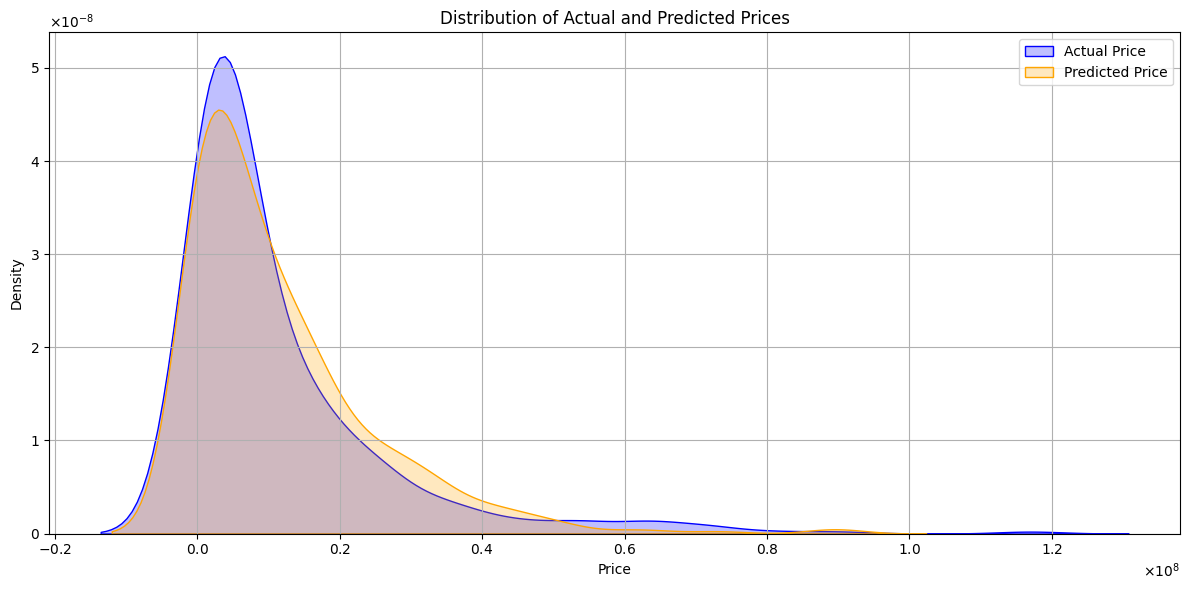

In [62]:
# Step 8: Create a comparison DataFrame to compare actual prices and predicted prices
comparison_linear_reg_model = pd.DataFrame({'Actual Price': y_val_test, 'Predicted Price': y_pred_linear_reg})

# Plotting the distribution plots
plt.figure(figsize=(12, 6))

# Plot for actual prices
sns.kdeplot(comparison_linear_reg_model['Actual Price'], label='Actual Price', fill=True, color='blue')

# Plot for predicted prices
sns.kdeplot(comparison_linear_reg_model['Predicted Price'], label='Predicted Price', fill=True, color='orange')

# Plot details
plt.title('Distribution of Actual and Predicted Prices')
plt.xlabel('Price')
plt.ylabel('Density')
plt.legend()
plt.grid(True)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().xaxis.set_major_formatter(formatter)

# Show the plot
plt.tight_layout()
plt.show()


In [63]:
# Display the comparison
example_linear_reg_model = comparison_linear_reg_model.iloc[40:91]
print("\nComparison of Actual Prices and Predicted Prices:")
print(example_linear_reg_model)


Comparison of Actual Prices and Predicted Prices:
      Actual Price  Predicted Price
501       15300000       15347452.0
1595       2250000        6908909.0
1781       1350000        6683718.0
596       13500000       26749128.0
1188       4500000              0.0
918        7200000        5500997.0
1872        990000        1492260.0
1881        900000              0.0
1988        720000        1595687.0
361       19800000        8145833.0
1254       4500000       13016532.0
156       34200000       31576360.0
1548       2250000        2990279.0
2099        270000              0.0
1460       2700000       25105366.0
1154       4500000       10387888.0
1255       4500000        4253587.0
252       25200000       30322329.0
251       25200000        7405761.0
1505       2700000         225977.0
393       18000000       20224675.0
1526       2520000        4060657.0
2003        675000         434294.0
1970        720000              0.0
748        9000000        9306345.0
1135       49

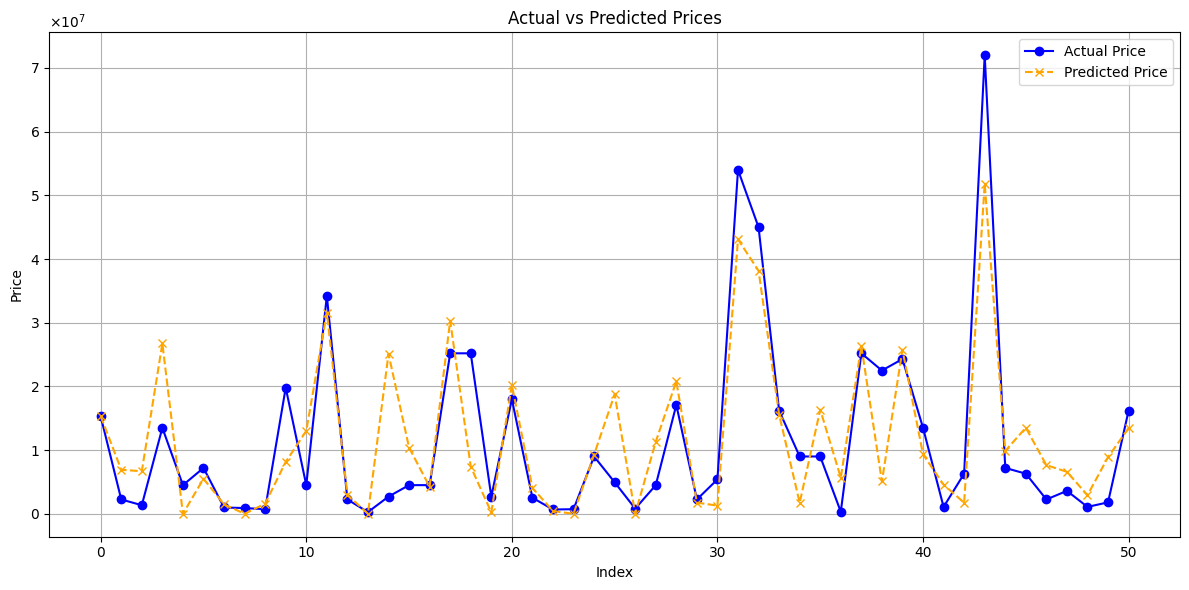

In [64]:
# Sample data for demonstration (replace with your actual data)
actual_prices_linear_reg = example_linear_reg_model['Actual Price'].tolist()
predicted_prices_linear_reg = example_linear_reg_model['Predicted Price'].tolist()

# Create a DataFrame
linear_reg_data_frame = pd.DataFrame({
    'Actual Price': actual_prices_linear_reg,
    'Predicted Price': predicted_prices_linear_reg
})

# Plotting the line plot
plt.figure(figsize=(12, 6))

# Plot line for actual prices
plt.plot(linear_reg_data_frame.index, linear_reg_data_frame['Actual Price'], label='Actual Price', marker='o', linestyle='-', color='blue')

# Plot line for predicted prices
plt.plot(linear_reg_data_frame.index, linear_reg_data_frame['Predicted Price'], label='Predicted Price', marker='x', linestyle='--', color='orange')

# Plot details
plt.title('Actual vs Predicted Prices')
plt.xlabel('Index')
plt.ylabel('Price')
plt.legend()
plt.grid(True)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Show the plot
plt.tight_layout()
plt.show()


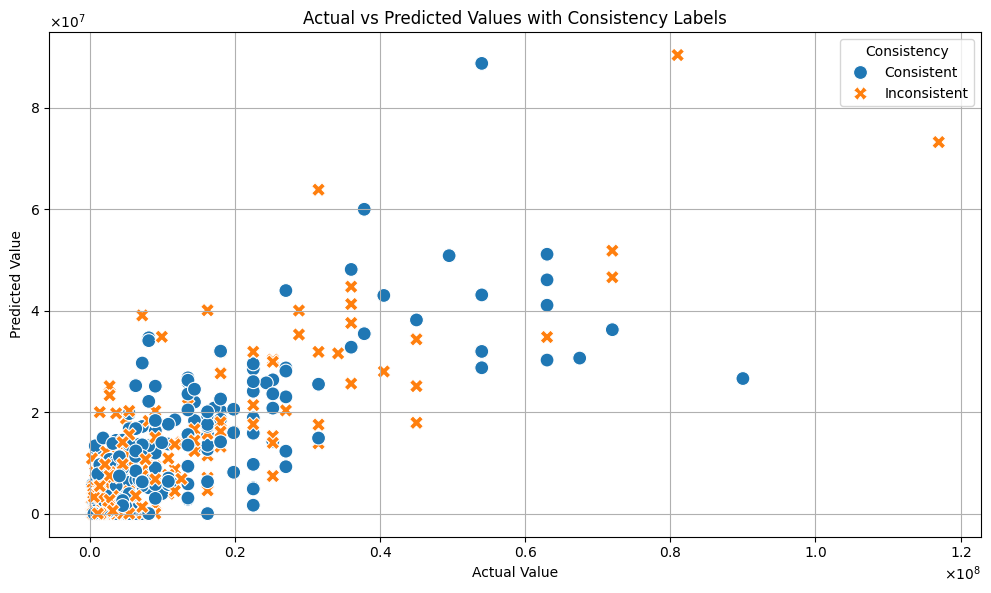

In [65]:
data_linear_reg = pd.DataFrame({
    'Actual Value': y_val_test,
    'Predicted Value': y_pred_linear_reg,
    'Consistency': x_val_test['Consistency_Label']
})

# Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data_linear_reg, x='Actual Value', y='Predicted Value', hue='Consistency', style='Consistency', s=100)

# Plot details
plt.title('Actual vs Predicted Values with Consistency Labels')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.grid(True)
plt.legend(title='Consistency')
plt.tight_layout()

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().xaxis.set_major_formatter(formatter)

plt.show()


In [66]:
def train_XGBRegressor_model(x_data, X_train, X_test, y_train):
  # Step 4: Preprocess the data
  # Identify numerical and categorical features
  num_features = x_data.select_dtypes(include=['float64', 'int64']).columns.tolist()
  cat_features = x_data.select_dtypes(include=['object']).columns.tolist()

  # Create a column transformer for preprocessing
  preprocessor = ColumnTransformer(
      transformers=[
          ('num', MinMaxScaler(), num_features),
          ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
      ])

  # Fit and transform the training data, and transform the testing data
  X_train = preprocessor.fit_transform(X_train)
  X_test = preprocessor.transform(X_test)

  # Define the parameter distribution for RandomizedSearchCV
  param_dist = {
      'n_estimators': [100, 200, 300],
      'max_depth': [3, 5, 7],
      'learning_rate': [0.01, 0.05, 0.1],
      'subsample': [0.7, 0.8, 0.9],
      'colsample_bytree': [0.7, 0.8, 0.9],
      'gamma': [0, 0.1, 0.2],
      'alpha': [0, 0.01, 0.1],
      'lambda': [1, 1.5, 2]
  }

  # Step 5: Create an XGBoost Regressor object with RandomizedSearchCV
  xgb_model = XGBRegressor(random_state=0)
  random_search = RandomizedSearchCV(estimator=xgb_model, param_distributions=param_dist, n_iter=50, cv=3, scoring='r2', n_jobs=-1, random_state=0)

  # Fit the model using the training data
  random_search.fit(X_train, y_train)

  # Get the best estimator and the best parameters
  best_xgb_model = random_search.best_estimator_
  best_params = random_search.best_params_

  # Print the best parameters
  print("Best Parameters:", best_params)

  return best_xgb_model, X_test

In [67]:
def test_XGBRegressor_model(model, x_test):
  #Generate predictions on the test set
  y_pred = model.predict(x_test)

  # Handle negative predictions by setting them to zero
  y_pred = np.maximum(y_pred, 0)

  # Round predictions to nearest integer to remove decimals
  y_pred = np.round(y_pred)
  return y_pred

In [68]:
xgb_model, x_trans_test = train_XGBRegressor_model(x_merged_data, x_val_train, x_val_test, y_val_train)

y_pred_xgb_model = test_XGBRegressor_model(xgb_model, x_trans_test)

xgb_model_R2_test, xgb_model_rmse, xgb_model_mae, xgb_model_mse = evaluate_model(xgb_model, y_val_test, x_trans_test, y_pred_xgb_model)

print(f'The R-squared score for the XGBoost model is: r2={round(xgb_model_R2_test, 3)}')
print(f'The Root Mean Squared Error (RMSE) for the XGBoost model is: RMSE={round(xgb_model_rmse, 3)}')

Best Parameters: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'lambda': 1, 'gamma': 0.1, 'colsample_bytree': 0.8, 'alpha': 0.01}
The R-squared score for the XGBoost model is: r2=0.631
The Root Mean Squared Error (RMSE) for the XGBoost model is: RMSE=9328314.901


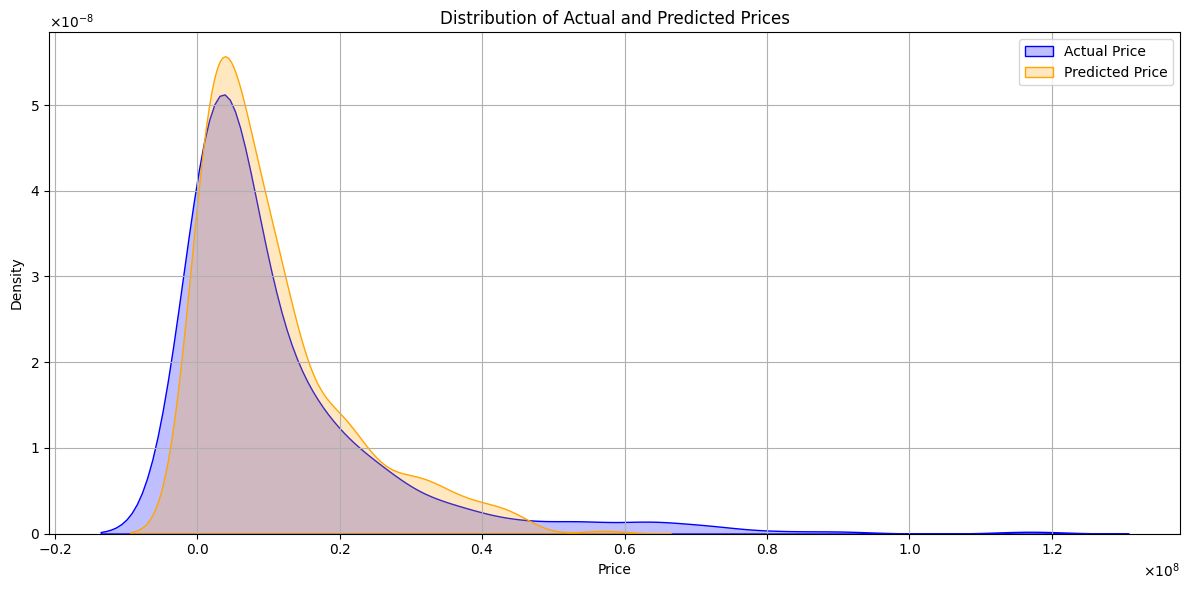

In [69]:
# Step 8: Create a comparison DataFrame to compare actual prices and predicted prices
comparison_xgb_model = pd.DataFrame({'Actual Price': y_val_test, 'Predicted Price': y_pred_xgb_model})

# Plotting the distribution plots
plt.figure(figsize=(12, 6))

# Plot for actual prices
sns.kdeplot(comparison_xgb_model['Actual Price'], label='Actual Price', fill=True, color='blue')

# Plot for predicted prices
sns.kdeplot(comparison_xgb_model['Predicted Price'], label='Predicted Price', fill=True, color='orange')

# Plot details
plt.title('Distribution of Actual and Predicted Prices')
plt.xlabel('Price')
plt.ylabel('Density')
plt.legend()
plt.grid(True)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().xaxis.set_major_formatter(formatter)

# Show the plot
plt.tight_layout()
plt.show()


In [70]:
# Display the comparison
example_xbg_model = comparison_xgb_model.iloc[40:91]
print("\nComparison of Actual Prices and Predicted Prices:")
print(example_xbg_model)


Comparison of Actual Prices and Predicted Prices:
      Actual Price  Predicted Price
501       15300000       10385110.0
1595       2250000        2104412.0
1781       1350000        2468428.0
596       13500000        8400407.0
1188       4500000         382244.0
918        7200000       28954044.0
1872        990000         483850.0
1881        900000        2149205.0
1988        720000        1446613.0
361       19800000       11549001.0
1254       4500000        7583934.0
156       34200000       20474954.0
1548       2250000        1807516.0
2099        270000         507471.0
1460       2700000        8880248.0
1154       4500000        2186615.0
1255       4500000       10682977.0
252       25200000       22913116.0
251       25200000       30122290.0
1505       2700000        1934233.0
393       18000000       18589060.0
1526       2520000        4443526.0
2003        675000              0.0
1970        720000              0.0
748        9000000       10026475.0
1135       49

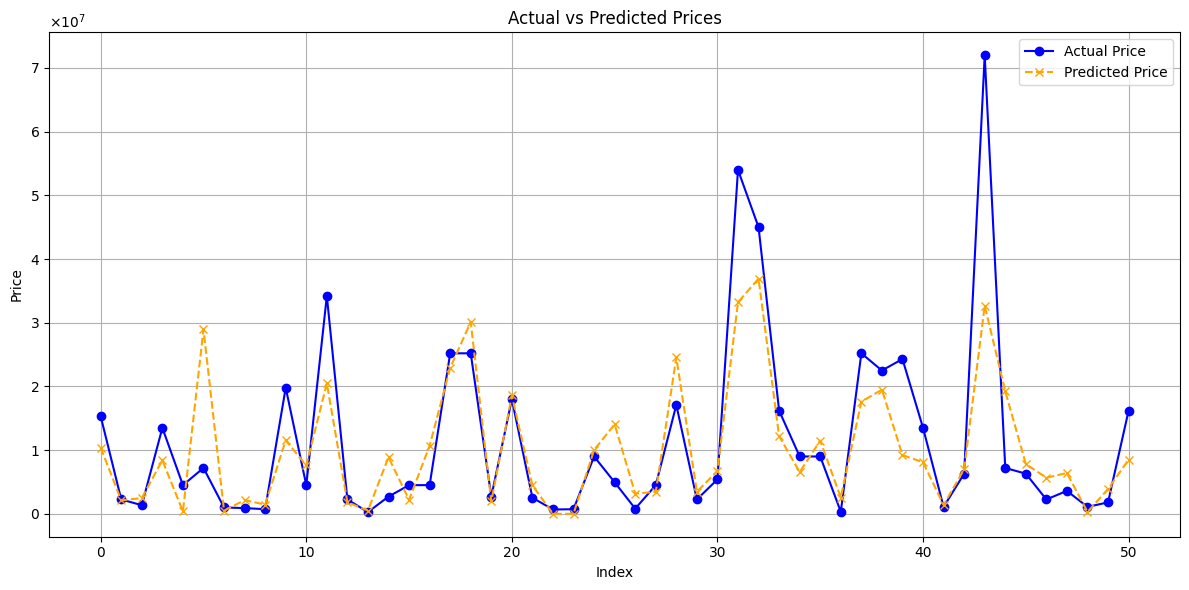

In [71]:
# Sample data for demonstration (replace with your actual data)
actual_prices_xbg = example_xbg_model['Actual Price'].tolist()
predicted_prices_xbg = example_xbg_model['Predicted Price'].tolist()

# Create a DataFrame
xbg_data_frame = pd.DataFrame({
    'Actual Price': actual_prices_xbg,
    'Predicted Price': predicted_prices_xbg
})

# Plotting the line plot
plt.figure(figsize=(12, 6))

# Plot line for actual prices
plt.plot(xbg_data_frame.index, xbg_data_frame['Actual Price'], label='Actual Price', marker='o', linestyle='-', color='blue')

# Plot line for predicted prices
plt.plot(xbg_data_frame.index, xbg_data_frame['Predicted Price'], label='Predicted Price', marker='x', linestyle='--', color='orange')

# Plot details
plt.title('Actual vs Predicted Prices')
plt.xlabel('Index')
plt.ylabel('Price')
plt.legend()
plt.grid(True)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Show the plot
plt.tight_layout()
plt.show()


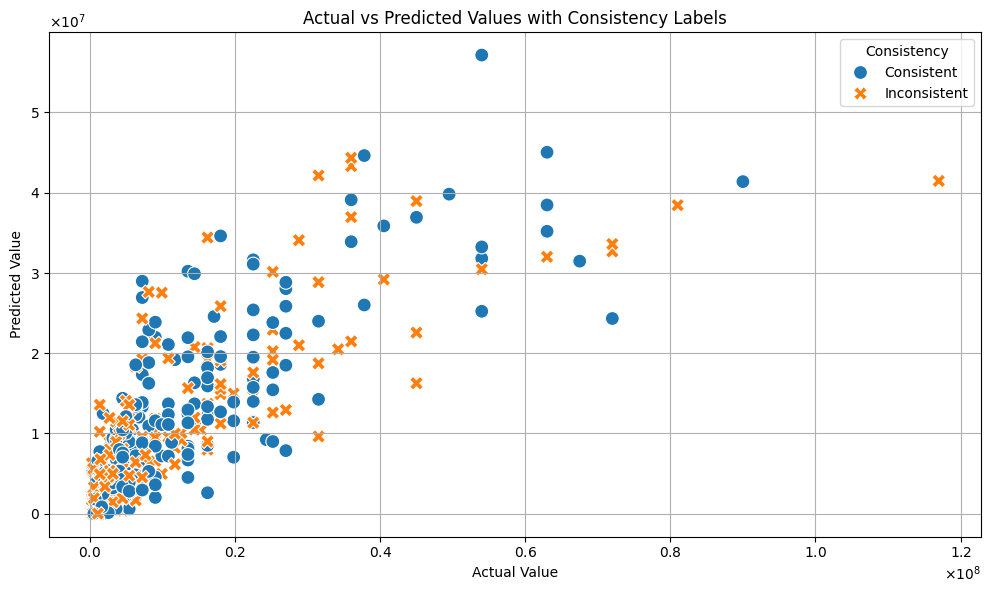

In [72]:
data_xgboost = pd.DataFrame({
    'Actual Value': y_val_test,
    'Predicted Value': y_pred_xgb_model,
    'Consistency': x_val_test['Consistency_Label']
})

# Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data_xgboost, x='Actual Value', y='Predicted Value', hue='Consistency', style='Consistency', s=100)

# Plot details
plt.title('Actual vs Predicted Values with Consistency Labels')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.grid(True)
plt.legend(title='Consistency')
plt.tight_layout()

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().xaxis.set_major_formatter(formatter)

plt.show()


In [73]:
def train_ridge_model(x_data, X_train, X_test, y_train):
  # Step 4: Preprocess the data
  # Identify numerical and categorical features
  num_features = x_data.select_dtypes(include=['float64', 'int64']).columns.tolist()
  cat_features = x_data.select_dtypes(include=['object']).columns.tolist()

  # Create a column transformer for preprocessing
  preprocessor = ColumnTransformer(
      transformers=[
          ('num', MinMaxScaler(), num_features),
          ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
      ])

  # Define the pipeline with preprocessing and Ridge regression
  ridge_pipeline = Pipeline(steps=[
      ('preprocessor', preprocessor),
      ('regressor', Ridge())
  ])

  # Define the parameter grid for GridSearchCV
  param_grid_ridge = {
      'regressor__alpha': [0.1, 1, 10, 100, 1000]  # Regularization strength
  }

  # Create a GridSearchCV object with Ridge
  grid_search_ridge = GridSearchCV(estimator=ridge_pipeline, param_grid=param_grid_ridge, cv=3, scoring='r2', n_jobs=-1)

  # Fit the model using the training data
  grid_search_ridge.fit(X_train, y_train)

  # Get the best estimator and the best parameters
  best_ridge_model = grid_search_ridge.best_estimator_
  best_params_ridge = grid_search_ridge.best_params_

  # Print the best parameters
  print("Best Parameters:", best_params_ridge)

  return best_ridge_model, X_test

In [74]:
def test_ridge_model(model, x_test):
  #Generate predictions on the test set
  y_pred = model.predict(x_test)

  # Handle negative predictions by setting them to zero
  y_pred = np.maximum(y_pred, 0)

  # Round predictions to nearest integer to remove decimals
  y_pred = np.round(y_pred)
  return y_pred

In [75]:
ridge_model, x_trans_test = train_ridge_model(x_merged_data, x_val_train, x_val_test, y_val_train)

y_pred_ridge_model = test_ridge_model(ridge_model, x_trans_test)

ridge_model_R2_test, ridge_model_rmse, ridge_model_mae, ridge_model_mse = evaluate_model(ridge_model, y_val_test, x_trans_test, y_pred_ridge_model)

print(f'The R-squared score for the Ridge model is: r2={round(ridge_model_R2_test, 3)}')
print(f'The Root Mean Squared Error (RMSE) for the Ridge model is: RMSE={round(ridge_model_rmse, 3)}')

Best Parameters: {'regressor__alpha': 10}
The R-squared score for the Ridge model is: r2=0.663
The Root Mean Squared Error (RMSE) for the Ridge model is: RMSE=8690594.012


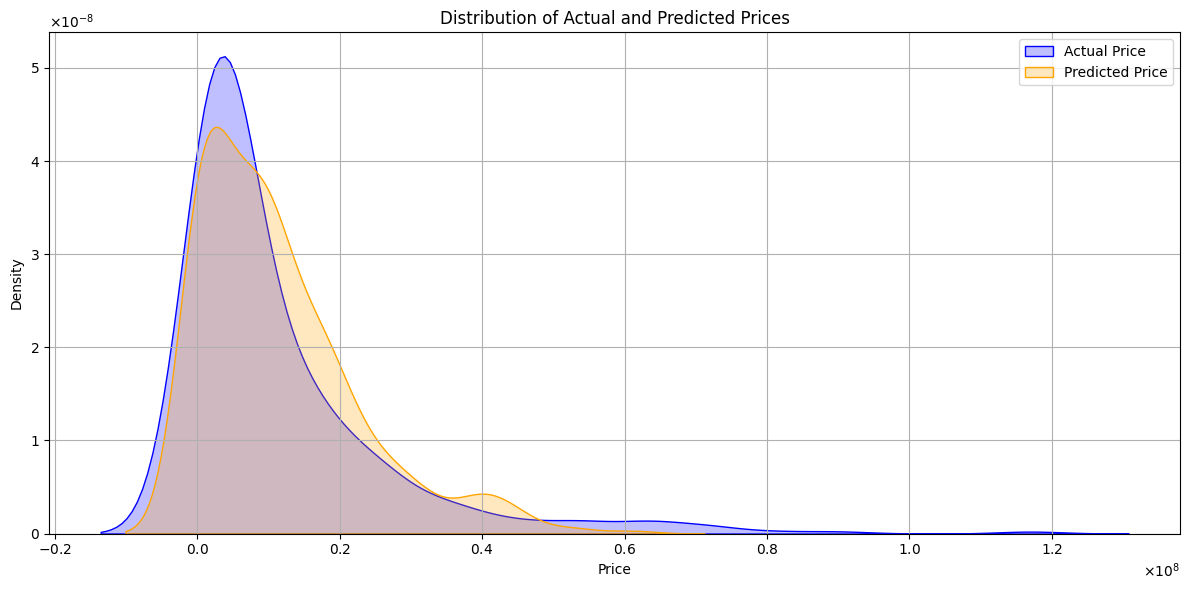

In [76]:
# Step 8: Create a comparison DataFrame to compare actual prices and predicted prices
comparison_ridge_model = pd.DataFrame({'Actual Price': y_val_test, 'Predicted Price': y_pred_ridge_model})

# Plotting the distribution plots
plt.figure(figsize=(12, 6))

# Plot for actual prices
sns.kdeplot(comparison_ridge_model['Actual Price'], label='Actual Price', fill=True, color='blue')

# Plot for predicted prices
sns.kdeplot(comparison_ridge_model['Predicted Price'], label='Predicted Price', fill=True, color='orange')

# Plot details
plt.title('Distribution of Actual and Predicted Prices')
plt.xlabel('Price')
plt.ylabel('Density')
plt.legend()
plt.grid(True)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().xaxis.set_major_formatter(formatter)

# Show the plot
plt.tight_layout()
plt.show()

In [77]:
# Display the comparison of 20 records
example_ridge_model = comparison_ridge_model.iloc[200:251]
print("\nComparison of Actual Prices and Predicted Prices:")
print(example_ridge_model)


Comparison of Actual Prices and Predicted Prices:
      Actual Price  Predicted Price
276       22500000       15625663.0
385       18000000       18378719.0
1557       2250000        4393891.0
530       14400000       20280013.0
1042       5400000        2217348.0
1793       1350000        9027451.0
1719       1800000        3029174.0
17        72000000       29576455.0
2031        540000              0.0
831        8100000       14830452.0
1979        720000              0.0
565        9000000       17238053.0
799        9000000        3625689.0
529       14400000       15340224.0
2090        360000              0.0
986        6300000        4753517.0
2100        270000        8339489.0
1018       6300000        7506718.0
1742       1620000        5178600.0
23        67500000       30843581.0
148       36000000       43100571.0
215       27000000       10889201.0
1728       1620000         732404.0
546       13500000       19353340.0
1055       5400000        8322831.0
333       198

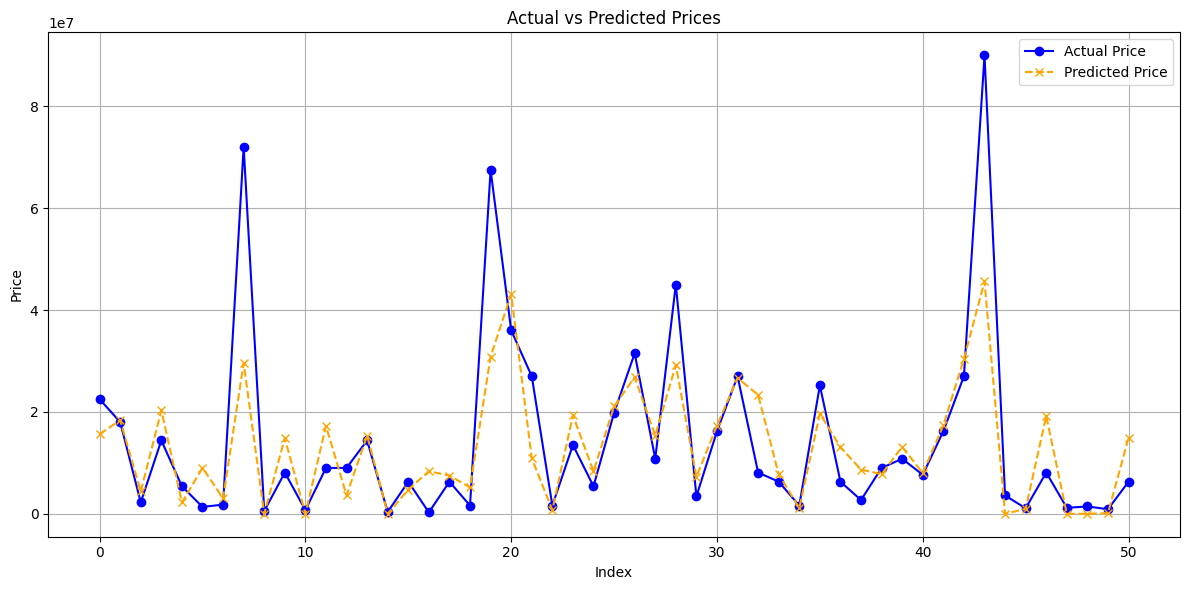

In [78]:
# Sample data for demonstration (replace with your actual data)
actual_prices_ridge = example_ridge_model['Actual Price'].tolist()
predicted_prices_ridge = example_ridge_model['Predicted Price'].tolist()

# Create a DataFrame
ridge_data_frame = pd.DataFrame({
    'Actual Price': actual_prices_ridge,
    'Predicted Price': predicted_prices_ridge
})

# Plotting the line plot
plt.figure(figsize=(12, 6))

# Plot line for actual prices
plt.plot(ridge_data_frame.index, ridge_data_frame['Actual Price'], label='Actual Price', marker='o', linestyle='-', color='blue')

# Plot line for predicted prices
plt.plot(ridge_data_frame.index, ridge_data_frame['Predicted Price'], label='Predicted Price', marker='x', linestyle='--', color='orange')

# Plot details
plt.title('Actual vs Predicted Prices')
plt.xlabel('Index')
plt.ylabel('Price')
plt.legend()
plt.grid(True)

# Show the plot
plt.tight_layout()
plt.show()


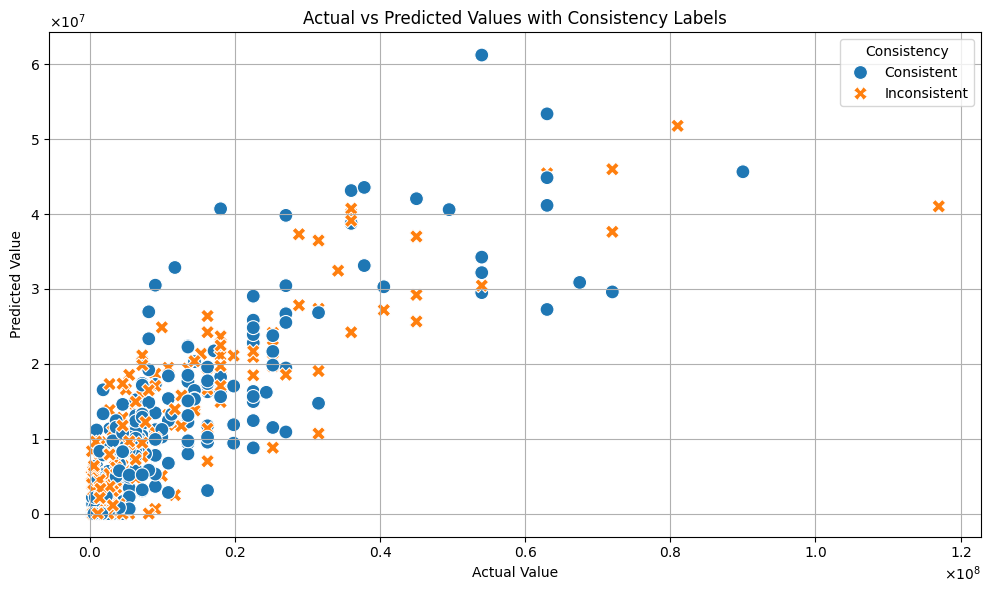

In [79]:
data_xgboost = pd.DataFrame({
    'Actual Value': y_val_test,
    'Predicted Value': y_pred_ridge_model,
    'Consistency': x_val_test['Consistency_Label']
})

# Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data_xgboost, x='Actual Value', y='Predicted Value', hue='Consistency', style='Consistency', s=100)

# Plot details
plt.title('Actual vs Predicted Values with Consistency Labels')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.grid(True)
plt.legend(title='Consistency')
plt.tight_layout()

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().xaxis.set_major_formatter(formatter)
plt.show()


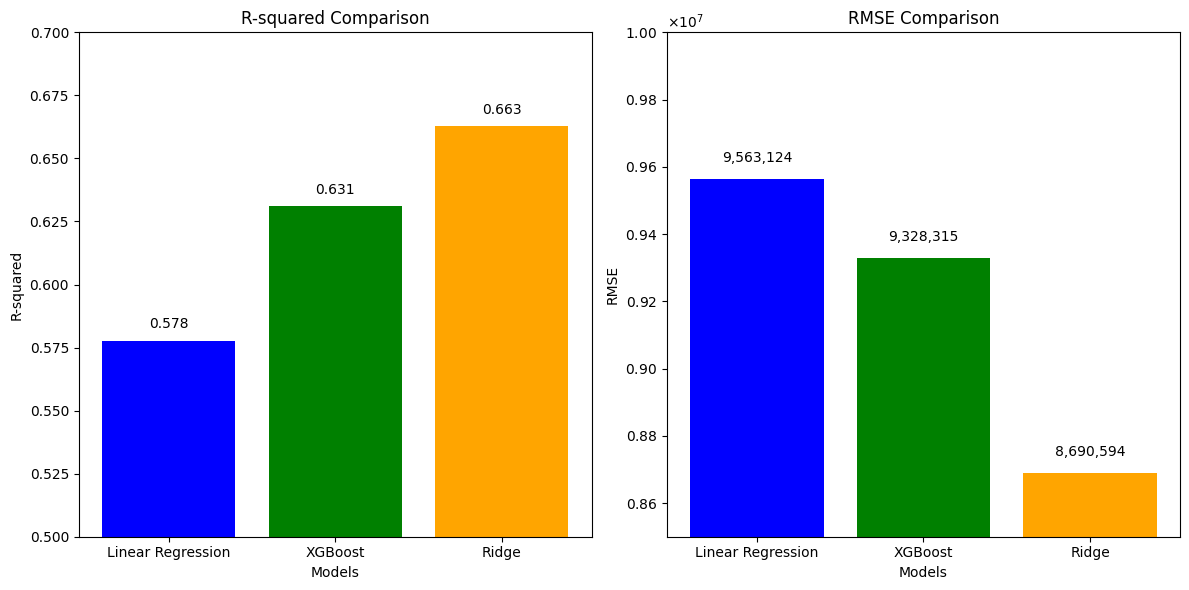

In [80]:
# Data for plotting
models = ['Linear Regression', 'XGBoost', 'Ridge']
r2_scores = [linear_reg_R2_test, xgb_model_R2_test, ridge_model_R2_test]
rmse_scores = [linear_reg_rmse, xgb_model_rmse, ridge_model_rmse]

# Create a figure with two subplots: one for R-squared and one for RMSE
fig, ax1 = plt.subplots(1, 2, figsize=(12, 6))

# Bar plot for R-squared
ax1[0].bar(models, r2_scores, color=['blue', 'green', 'orange'])
ax1[0].set_title('R-squared Comparison')
ax1[0].set_xlabel('Models')
ax1[0].set_ylabel('R-squared')
ax1[0].set_ylim(0.5, 0.7)

# Adding data labels on top of the bars for R-squared
for i in range(len(r2_scores)):
    ax1[0].text(i, r2_scores[i] + 0.005, f'{r2_scores[i]:.3f}', ha='center')

# Bar plot for RMSE
ax1[1].bar(models, rmse_scores, color=['blue', 'green', 'orange'])
ax1[1].set_title('RMSE Comparison')
ax1[1].set_xlabel('Models')
ax1[1].set_ylabel('RMSE')
ax1[1].set_ylim(8500000, 10000000)

# Adding data labels on top of the bars for RMSE
for i in range(len(rmse_scores)):
    ax1[1].text(i, rmse_scores[i] + 50000, f'{rmse_scores[i]:,.0f}', ha='center')

# Set a tight layout for better spacing
plt.tight_layout()

# Formatting the y-axis to scientific notation
formatter = plt.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-1,1))
plt.gca().yaxis.set_major_formatter(formatter)

# Show the plot
plt.show()
